# Large-scale staff allocation — forecasts as features
## Classical vs prescriptive vs distributionally robust (DR) prescriptive learning

**Instance.** $E=40$ employees, $J=20$ shifts (one time slot each), $800$ binary assignment decisions per schedule
(the paper's previous instance: $E=10$, $J=5$, i.e. $50$ decisions).

**Features are forecasts, not realisations.** For sample $i$ and shift $j$ the decision maker observes the
forecast utilisation $f_{ij}$; the realised requirement is
$$d_{ij} = u_{ij}\,\bar d_j,\qquad u_{ij} = f_{ij} + \sigma\eta_{ij},\quad \eta_{ij}\sim\mathcal N(0,1).$$
The policy $\pi_{ej}(\mathbf z)=w_{ej}z_j+w^0_{ej}$ uses $\mathbf z=(f_{i1},\dots,f_{iJ})$ only; $d_{ij}$ enters training only
through the coverage constraints and is used out of sample only to score the schedule.

| Set | Forecast regime | Samples |
|---|---|---|
| Training | $f\sim\mathcal U(0.25,0.55)$ | $S\in\{50,100,200,500\}$ |
| Validation | $f\sim\mathcal U(0.25,0.55)$ | 200 |
| Close test | $f\sim\mathcal U(0.25,0.55)$ | 1,000 |
| Far test | $f\sim\mathcal U(0.65,0.90)$ (distribution shift) | 1,000 |

**Models.** Classical: hindsight-optimal labels for the realised demand, $\ell_1$ regression on forecasts (2).
Prescriptive: model (38). DR prescriptive: (39)–(44) — DR policy-consistency (dual norm $|w|+1$) and a DR
coverage chance constraint (dual norm $1+E$, worst-case CVaR form).

**Solver.** `sa2.py` solves the training problems through an exact threshold-pattern reformulation (scalar
feature per pair $(e,j)$, $w_{ej}\ge 0$) by block-coordinate descent over shifts, each block solved to optimality
with HiGHS. On the paper's original 10×5×20 instance it reproduces the solution of (38) exactly.

**This notebook is self-contained**: all model/solver code is in the cells below and the cached results of the runs
reported in the paper are embedded (Section 0c). Requirements: `pip install numpy scipy pandas matplotlib highspy`.

In [1]:
import os, sys, time, math, pickle, glob
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, matplotlib.ticker as mt
from scipy.stats import wasserstein_distance

RUN_EXPERIMENTS = False     # True: re-run all training (about 1 h on 2 cores); False: use embedded results
os.makedirs('figures', exist_ok=True)

# ── Plot style (same as sa_comparison_oos.ipynb) ──────────────────────────────
from matplotlib.patches import Patch
from matplotlib.lines import Line2D
COL = {'classical': '#4878CF', 'prescriptive': '#E87036', 'drcc': '#CC3333'}
HCOL = '#6ACC65'                                    # hindsight benchmark
LAB = {'classical': 'Classical', 'prescriptive': 'Prescriptive',
       'drcc': 'Distributionally robust\nprescriptive'}
MODELS = ['classical', 'prescriptive', 'drcc']
plt.rcParams.update(plt.rcParamsDefault)
plt.rcParams.update({'font.size': 11, 'axes.titleweight': 'bold', 'axes.labelweight': 'bold',
                     'savefig.bbox': 'tight', 'figure.dpi': 100})

def boldticks(ax):
    for t in ax.get_xticklabels() + ax.get_yticklabels():
        t.set_fontweight('bold')

def boldlegend(leg):
    for t in leg.get_texts():
        t.set_fontweight('bold')

def legend_models(ax, loc='upper left', hindsight=True, **kw):
    h = [Patch(fc=COL[m], ec='k', label=LAB[m].replace('\n', ' ')) for m in MODELS]
    if hindsight:
        h += [Line2D([0], [0], color=HCOL, lw=2, ls='--', label='Hindsight')]
    leg = ax.legend(handles=h, fontsize=9, frameon=True, loc=loc, borderpad=0.5, labelspacing=0.4, **kw)
    boldlegend(leg); return leg

def save(fig, name):
    fig.savefig(f'figures/{name}.pdf'); fig.savefig(f'figures/{name}.png', dpi=200)
fmt = mt.FuncFormatter(lambda v, _: f'{v:,.0f}')


## 0a  Pattern penalties (hot-started LPs)

In [2]:
import numpy as np, highspy
INF = highspy.kHighsInf
DELTA = 1e-6

def patterns_shift(zj, rho=0.0, eps=None):
    """g[l], w[l], c[l] for all increasing threshold patterns of one shift (hot-started LPs)."""
    n = len(zj); dr = rho > 0
    order = np.argsort(zj); rank = np.empty(n, int); rank[order] = np.arange(n)
    h = highspy.Highs(); h.setOptionValue('output_flag', False)
    # cols: w(>=0), c, v, zeta_k, [t+, t-, r+_k, r-_k]
    iw, ic, iv, iz = 0, 1, 2, 3
    ncol = 3 + n + (2 + 2 * n if dr else 0)
    itp, itm, irp, irm = 3 + n, 4 + n, 5 + n, 5 + 2 * n
    lb = np.zeros(ncol); ub = np.full(ncol, INF); cost = np.zeros(ncol)
    lb[ic] = -INF; cost[iz:iz + n] = 1.0
    if dr: lb[itp] = lb[itm] = -INF
    h.addVars(ncol, lb, ub); h.changeColsCost(ncol, np.arange(ncol, dtype=np.int32), cost)
    x = np.ones(n)  # l = 0: all ones
    band, zp, zm, dp, dm = [], [], [], [], []
    def row(lo, up, idx, val):
        h.addRow(lo, up, len(idx), np.array(idx, np.int32), np.array(val, float)); return h.getNumRow() - 1
    for k in range(n):
        band.append(row(0.5 + DELTA, 1.5, [iw, ic], [zj[k], 1]))
        zp.append(row(-INF, x[k], [iw, ic, iz + k], [zj[k], 1, -1]))        # pi - zeta <= x
        zm.append(row(x[k], INF, [iw, ic, iz + k], [zj[k], 1, 1]))          # pi + zeta >= x
        if dr:
            dp.append(row(-INF, x[k] + 0.5, [itp, irp + k, iw, ic], [1, -1, zj[k], 1]))
            dm.append(row(-INF, -x[k] + 0.5, [itm, irm + k, iw, ic], [1, -1, -zj[k], -1]))
    row(-INF, 0.0, [iw, iv], [1, -1])
    if dr:
        S = n
        for it, ir in ((itp, irp), (itm, irm)):
            row(rho * S, INF, [it] + [ir + k for k in range(n)] + [iv],
                [eps * S] + [-1.0] * n + [-rho * S])
    g = np.full(n + 1, np.inf); W = np.full(n + 1, np.nan); C = np.full(n + 1, np.nan)
    for l in range(n + 1):
        if l > 0:   # flip scenario with rank l-1 from 1 to 0
            k = order[l - 1]; x[k] = 0.0
            h.changeRowBounds(band[k], -0.5, 0.5 - DELTA)
            h.changeRowBounds(zp[k], -INF, 0.0); h.changeRowBounds(zm[k], 0.0, INF)
            if dr:
                h.changeRowBounds(dp[k], -INF, 0.5); h.changeRowBounds(dm[k], -INF, 0.5)
        h.run()
        if h.getModelStatus() == highspy.HighsModelStatus.kOptimal:
            s = h.getSolution().col_value
            g[l] = h.getInfo().objective_function_value; W[l] = s[iw]; C[l] = s[ic]
    return dict(order=order, rank=rank, g=g, wc=np.c_[W, C])

def build_patterns_fast(z, rho=0.0, eps=None):
    return [patterns_shift(z[:, j], rho, eps) for j in range(z.shape[1])]


## 0b  Model, solver, evaluation (training problems (2), (38), (39)-(44))

In [3]:
"""Staff allocation with forecast features -- classical / prescriptive / DR prescriptive.

Policy  : x_ej(z) = 1{ w_ej z_j + c_ej >= 0.5 },  z_j = demand FORECAST of shift j.
Training: model (38) of the paper (prescriptive) and its distributionally robust
          version (39)-(44): DR policy-consistency constraints (kept together with the
          nominal ones, cf. Remark 2) and a DR chance constraint replacing coverage (38d).

Solution method
---------------
For a scalar feature, a training pattern x_{.ej} satisfies the policy-consistency
constraints iff it is a threshold pattern in the order of z_{.j}. We restrict to
non-decreasing patterns (w_ej >= 0: a higher forecast never removes staff).
For every shift j and threshold position l the smallest policy penalty
sum_k |pi - x| (nominal, or with the DR policy constraints) is a small LP; it does
not depend on the employee. The training MIP is then a choice of one threshold
per (e,j). Given the thresholds of all other shifts, the problem restricted to one
shift is a min-cost-flow-type LP (nominal coverage) or a small MIP (DR coverage).
We solve the training MIP by block-coordinate descent over shifts (exact per
block) and report the LP lower bound of the full nominal problem.
"""
import math, time
import numpy as np
import highspy
from scipy.optimize import linprog
from scipy.sparse import coo_matrix

INF = highspy.kHighsInf
DELTA = 1e-6


# --------------------------------------------------------------------------- #
class Instance:
    def __init__(self, c_e, smax_e, D_max, c_ls=500.0):
        self.c_e = np.asarray(c_e, float); self.E = len(self.c_e)
        self.smax_e = np.asarray(smax_e, int)
        self.D_max = np.asarray(D_max, float); self.J = len(self.D_max)
        self.c_ls = float(c_ls)


# --------------------------------------------------------------------------- #
# Policy evaluation
# --------------------------------------------------------------------------- #
def predict(w, c, z):
    pi = w[None] * z[:, None, :] + c[None]
    return (pi >= 0.5).astype(float)


def evaluate(inst, x, d):
    """Mean per-scenario staffing, shortage and total cost of schedule x vs realised d."""
    staff = (x * inst.c_e[None, :, None]).sum(axis=(1, 2))
    short = inst.c_ls * np.maximum(0.0, d - x.sum(axis=1)).sum(axis=1)
    viol = np.maximum(0, x.sum(axis=2) - inst.smax_e[None]).sum()
    return dict(staff=staff.mean(), shortage=short.mean(), total=(staff + short).mean(),
                p_short=float((short > 1e-9).mean()), workload_viol=float(viol))


# --------------------------------------------------------------------------- #
# Pattern penalties
# --------------------------------------------------------------------------- #
def _fit(zj, xp, rho=0.0, eps=None):
    """min sum|pi-x| s.t. nominal band (+ DR policy constraints (39),(41) if rho>0).
    variables: w, c, v, zeta(n) [, t+, t-, r+(n), r-(n)]"""
    n = len(zj); dr = rho > 0
    nv = 3 + n + (2 + 2 * n if dr else 0)
    iw, ic, iv = 0, 1, 2; iz = 3
    itp, itm = 3 + n, 4 + n; irp = 5 + n; irm = 5 + 2 * n
    rows, cols, vals, ub = [], [], [], []
    def add(coefs, rhs):
        r = len(ub)
        for col, val in coefs:
            rows.append(r); cols.append(col); vals.append(val)
        ub.append(rhs)
    for k in range(n):
        p = [(iw, zj[k]), (ic, 1.0)]
        mp = [(iw, -zj[k]), (ic, -1.0)]
        add(p + [(iz + k, -1)], xp[k]); add(mp + [(iz + k, -1)], -xp[k])
        if xp[k] > 0.5:
            add(mp, -(0.5 + DELTA)); add(p, 1.5)
        else:
            add(p, 0.5 - DELTA); add(mp, 0.5)
        if dr:
            # t+ - r+_k <= -pi_k + x_k + 0.5 ;  t- - r-_k <= pi_k - x_k + 0.5
            add([(itp, 1), (irp + k, -1)] + p, xp[k] + 0.5)
            add([(itm, 1), (irm + k, -1)] + mp, -xp[k] + 0.5)
    add([(iw, 1), (iv, -1)], 0.0); add([(iw, -1), (iv, -1)], 0.0)
    if dr:
        S = n
        for it, ir in ((itp, irp), (itm, irm)):
            # eps S t - sum r >= rho S (|w| + 1)
            add([(it, -eps * S)] + [(ir + k, 1) for k in range(n)] + [(iv, rho * S)], -rho * S)
    A = coo_matrix((vals, (rows, cols)), shape=(len(ub), nv)).tocsr()
    cobj = np.zeros(nv); cobj[iz:iz + n] = 1.0
    bounds = [(0, None), (None, None), (0, None)] + [(0, None)] * n
    if dr:
        bounds += [(None, None), (None, None)] + [(0, None)] * (2 * n)
    res = linprog(cobj, A_ub=A, b_ub=np.array(ub), bounds=bounds, method='highs')
    if res.status != 0:
        return None
    return res.fun, res.x[iw], res.x[ic]


def build_patterns_slow(z, rho=0.0, eps=None):
    """For each shift: order of scenarios, penalty g[l] (inf = infeasible), (w,c)[l]."""
    n, J = z.shape; out = []
    for j in range(J):
        order = np.argsort(z[:, j]); rank = np.empty(n, int); rank[order] = np.arange(n)
        g = np.full(n + 1, np.inf); wc = np.full((n + 1, 2), np.nan)
        for l in range(n + 1):
            f = _fit(z[:, j], (rank >= l).astype(float), rho, eps)
            if f is not None:
                g[l] = f[0]; wc[l] = f[1:]
        out.append(dict(order=order, rank=rank, g=g, wc=wc))
    return out


# --------------------------------------------------------------------------- #
# Single-shift subproblem
# --------------------------------------------------------------------------- #
def solve_shift(inst, pat, dj, Dmax_j, blocked, c_zeta, dr=None, time_limit=60):
    """Choose one threshold l_e in {0..S} (S = never) per employee for one shift.
    blocked[e] = largest rank r at which employee e has no workload capacity left
    (-1 if none) -> l_e must exceed it.  dj: realised demand per scenario (len S).
    dr = None (nominal coverage) or dict(rho, eps) (DR chance constraint (43)-(44))."""
    E = inst.E; S = len(dj)
    g = pat['g']; order = pat['order']
    d_sorted = dj[order]
    h = highspy.Highs(); h.setOptionValue('output_flag', False)
    h.setOptionValue('time_limit', float(time_limit))
    h.setOptionValue('mip_rel_gap', 1e-3)
    # y[e,l] : e * (S+1) + l
    ny = E * (S + 1)
    lb = np.zeros(ny); ub = np.ones(ny); cost = np.zeros(ny)
    for e in range(E):
        for l in range(S + 1):
            i = e * (S + 1) + l
            if not np.isfinite(g[l]) or l <= blocked[e]:
                ub[i] = 0.0; cost[i] = 0.0
            else:
                cost[i] = (inst.c_e[e] * (S - l) + c_zeta * g[l]) / S
    h.addCols(ny, cost, lb, ub, 0, np.array([], np.int32), np.array([], np.int32), np.array([]))
    # cumulative count N_r, r = 0..S-1   (N_r = N_{r-1} + sum_e y[e,r])
    iN = ny
    h.addCols(S, np.zeros(S), np.zeros(S), np.full(S, float(E)), 0,
              np.array([], np.int32), np.array([], np.int32), np.array([]))
    for e in range(E):
        idx = np.arange(e * (S + 1), (e + 1) * (S + 1), dtype=np.int32)
        h.addRow(1.0, 1.0, len(idx), idx, np.ones(len(idx)))
    for r in range(S):
        idx = [iN + r] + [e * (S + 1) + r for e in range(E)]
        val = [1.0] + [-1.0] * E
        if r > 0:
            idx.append(iN + r - 1); val.append(-1.0)
        h.addRow(0.0, 0.0, len(idx), np.array(idx, np.int32), np.array(val))
    ints = list(range(ny))
    if dr is None:
        for r in range(S):
            h.changeColBounds(iN + r, float(math.ceil(d_sorted[r] - 1e-9)), float(E))
    else:
        rho, eps = dr['rho'], dr['eps']
        norm = dr.get('norm', 1.0 + E)    # ||a||_* of (44a): 1 (demand) + E (assignments)
        it = iN + S; iq = it + 1; ir = iq + S
        h.addCols(1, np.zeros(1), np.zeros(1), np.full(1, INF), 0,
                  np.array([], np.int32), np.array([], np.int32), np.array([]))
        h.addCols(S, np.zeros(S), np.zeros(S), np.ones(S), 0,
                  np.array([], np.int32), np.array([], np.int32), np.array([]))
        h.addCols(S, np.zeros(S), np.zeros(S), np.full(S, INF), 0,
                  np.array([], np.int32), np.array([], np.int32), np.array([]))
        exact = dr.get('exact', False)
        if exact:
            ints += list(range(iq, iq + S))
        else:   # worst-case CVaR form: q fixed to 0 (exact whenever all slacks >= 0)
            h.changeColsBounds(S, np.arange(iq, iq + S, dtype=np.int32), np.zeros(S), np.zeros(S))
        # eps S t - sum r >= rho S norm
        idx = np.array([it] + list(range(ir, ir + S)), np.int32)
        h.addRow(rho * S * norm, INF, len(idx), idx, np.r_[eps * S, -np.ones(S)])
        if exact:
            h.addRow(-INF, float(math.floor(eps * S)), S, np.arange(iq, iq + S, dtype=np.int32), np.ones(S))
        for r in range(S):
            dk = float(d_sorted[r])
            # N_r - d + d q_r - t + r_r >= 0
            h.addRow(dk, INF, 4, np.array([iN + r, iq + r, it, ir + r], np.int32),
                     np.array([1.0, dk, -1.0, 1.0]))
            if exact:
                h.addRow(-INF, float(E), 3, np.array([iq + r, it, ir + r], np.int32),
                         np.array([float(E), 1.0, -1.0]))
    nc = h.getNumCol()
    integrality = np.zeros(nc, np.int32); integrality[ints] = 1
    h.changeColsIntegrality(nc, np.arange(nc, dtype=np.int32), integrality)
    h.run()
    if h.getInfo().primal_solution_status != 2:
        return None, np.inf
    sol = np.array(h.getSolution().col_value)
    Y = sol[:ny].reshape(E, S + 1)
    l = Y.argmax(axis=1)
    return l, h.getInfo().objective_function_value


# --------------------------------------------------------------------------- #
# Block-coordinate descent over shifts
# --------------------------------------------------------------------------- #
def _x_from_l(L, pats, n):
    E, J = L.shape
    X = np.zeros((n, E, J))
    for j in range(J):
        X[:, :, j] = (pats[j]['rank'][:, None] >= L[None, :, j])
    return X


def objective(inst, L, pats, d, c_zeta):
    n = len(d); X = _x_from_l(L, pats, n)
    staff = (X * inst.c_e[None, :, None]).sum() / n
    pen = sum(pats[j]['g'][L[e, j]] for e in range(inst.E) for j in range(inst.J)) / n
    return staff + c_zeta * pen


def train_bcd(inst, z, d, pats, c_zeta=10.0, dr=None, sweeps=6, verbose=False, L0=None, seed=0):
    n, J = z.shape; E = inst.E
    rng = np.random.default_rng(seed)
    L = np.full((E, J), n, int) if L0 is None else L0.copy()   # start: nobody assigned
    shifts_order = np.argsort(-inst.D_max)
    hist = []
    for sw in range(sweeps):
        changed = 0
        seq = shifts_order if sw == 0 else rng.permutation(J)
        for j in seq:
            X = _x_from_l(L, pats, n); X[:, :, j] = 0
            used = X.sum(axis=2)                        # (n,E)
            full = used >= inst.smax_e[None]            # no capacity left
            blocked = np.array([pats[j]['rank'][full[:, e]].max() if full[:, e].any() else -1
                                for e in range(E)])
            lj, val = solve_shift(inst, pats[j], d[:, j], inst.D_max[j], blocked, c_zeta, dr)
            if lj is None:
                if verbose: print(f'  shift {j}: infeasible')
                if sw == 0:
                    return None, dict(status='infeasible', hist=hist)
                continue
            if np.any(lj != L[:, j]):
                old = L[:, j].copy(); L[:, j] = lj
                changed += int((old != lj).sum())
        obj = objective(inst, L, pats, d, c_zeta)
        hist.append(obj)
        if verbose: print(f'  sweep {sw}: obj={obj:.3f} changed={changed}')
        if sw > 0 and changed == 0:
            break
    w = np.array([[pats[j]['wc'][L[e, j]][0] for j in range(J)] for e in range(E)])
    c = np.array([[pats[j]['wc'][L[e, j]][1] for j in range(J)] for e in range(E)])
    return (w, c, L), dict(status='ok', obj=hist[-1], hist=hist)


# --------------------------------------------------------------------------- #
# LP lower bound of the full (nominal) prescriptive training problem
# --------------------------------------------------------------------------- #
def lp_bound(inst, z, d, pats, c_zeta=10.0, time_limit=600):
    """Relaxation of the threshold formulation (exact for (38) under w>=0)."""
    n, J = z.shape; E = inst.E
    h = highspy.Highs(); h.setOptionValue('output_flag', False)
    h.setOptionValue('solver', 'ipm'); h.setOptionValue('time_limit', float(time_limit))
    # b[e,j,r] = x for the scenario of rank r (monotone in r)
    nb = E * J * n
    bid = lambda e, j, r: (e * J + j) * n + r
    cost = np.zeros(nb); const = 0.0
    for e in range(E):
        for j in range(J):
            g = pats[j]['g'].copy(); g[~np.isfinite(g)] = 1e4
            for r in range(n):
                cost[bid(e, j, r)] = (inst.c_e[e] + c_zeta * (g[r] - g[r + 1])) / n
            const += c_zeta * g[n] / n
    h.addCols(nb, cost, np.zeros(nb), np.ones(nb), 0, np.array([], np.int32),
              np.array([], np.int32), np.array([]))
    R, C, V, LO, UP = [], [], [], [], []
    row = 0
    def addrow(cols_, vals_, lo, up):
        nonlocal row
        R.extend([row] * len(cols_)); C.extend(cols_); V.extend(vals_); LO.append(lo); UP.append(up); row += 1
    for e in range(E):
        for j in range(J):
            for r in range(n - 1):
                addrow([bid(e, j, r), bid(e, j, r + 1)], [1.0, -1.0], -INF, 0.0)
    for k in range(n):
        for j in range(J):
            r = pats[j]['rank'][k]
            addrow([bid(e, j, r) for e in range(E)], [1.0] * E, float(math.ceil(d[k, j] - 1e-9)), INF)
        for e in range(E):
            addrow([bid(e, j, pats[j]['rank'][k]) for j in range(J)], [1.0] * J, -INF, float(inst.smax_e[e]))
    A = coo_matrix((V, (R, C)), shape=(row, nb)).tocsr()
    h.addRows(row, np.array(LO), np.array(UP), A.nnz, A.indptr[:-1].astype(np.int32),
              A.indices.astype(np.int32), A.data)
    t0 = time.time(); h.run()
    return h.getInfo().objective_function_value + const, time.time() - t0


# --------------------------------------------------------------------------- #
# Deterministic MIPs (oracle labels, hindsight)
# --------------------------------------------------------------------------- #
def solve_det(inst, d, slack=False, time_limit=30):
    E, J = inst.E, inst.J
    h = highspy.Highs(); h.setOptionValue('output_flag', False)
    h.setOptionValue('time_limit', float(time_limit)); h.setOptionValue('mip_rel_gap', 1e-6)
    nx = E * J
    cost = np.repeat(inst.c_e, J)
    h.addCols(nx, cost, np.zeros(nx), np.ones(nx), 0, np.array([], np.int32),
              np.array([], np.int32), np.array([]))
    if slack:
        h.addCols(J, np.full(J, inst.c_ls), np.zeros(J), np.full(J, INF), 0,
                  np.array([], np.int32), np.array([], np.int32), np.array([]))
    for j in range(J):
        idx = [e * J + j for e in range(E)] + ([nx + j] if slack else [])
        h.addRow(float(math.ceil(d[j] - 1e-9)) if not slack else float(d[j]), INF, len(idx),
                 np.array(idx, np.int32), np.ones(len(idx)))
    for e in range(E):
        idx = np.arange(e * J, (e + 1) * J, dtype=np.int32)
        h.addRow(-INF, float(inst.smax_e[e]), J, idx, np.ones(J))
    integ = np.zeros(h.getNumCol(), np.int32); integ[:nx] = 1
    h.changeColsIntegrality(h.getNumCol(), np.arange(h.getNumCol(), dtype=np.int32), integ)
    h.run()
    if h.getInfo().primal_solution_status != 2:
        return None
    return np.round(np.array(h.getSolution().col_value)[:nx]).reshape(E, J)


def train_classical(inst, z, d, c_zeta=10.0):
    """Oracle labels from realised demand; L1 regression of labels on the forecast."""
    n, J = z.shape; E = inst.E
    labels = np.zeros((n, E, J))
    for k in range(n):
        xk = solve_det(inst, d[k])
        if xk is None:
            xk = solve_det(inst, d[k], slack=True)
        labels[k] = xk
    w = np.zeros((E, J)); c = np.zeros((E, J))
    for e in range(E):
        for j in range(J):
            # LAD: min sum |w z + c - x|   (variables w, c, s_k)
            zj = z[:, j]; xj = labels[:, e, j]
            A = np.zeros((2 * n, 2 + n)); b = np.zeros(2 * n)
            A[:n, 0] = zj; A[:n, 1] = 1; A[:n, 2:] = -np.eye(n); b[:n] = xj
            A[n:, 0] = -zj; A[n:, 1] = -1; A[n:, 2:] = -np.eye(n); b[n:] = -xj
            res = linprog(np.r_[0, 0, np.ones(n)], A_ub=A, b_ub=b,
                          bounds=[(None, None)] * 2 + [(0, None)] * n, method='highs')
            w[e, j], c[e, j] = res.x[:2]
    return w, c, labels


def hindsight(inst, d):
    return np.array([solve_det(inst, dk, slack=True) for dk in d])


build_patterns = build_patterns_fast


def train_bcd_multi(inst, z, d, pats, c_zeta=10.0, dr=None, restarts=3, ils=10, n_release=None,
                    sweeps=10, seed=0, verbose=False, time_budget=None):
    """Multi-start BCD + iterated local search (release a random subset of employees)."""
    t0 = time.time(); best = None; bobj = np.inf; E = inst.E; n = len(z)
    for s in range(restarts):
        res, info = train_bcd(inst, z, d, pats, c_zeta, dr, sweeps=sweeps, seed=seed + s)
        if res is not None and info['obj'] < bobj:
            best, bobj = res, info['obj']
    if best is None:
        return None, dict(status='infeasible')
    rng = np.random.default_rng(seed + 100); n_release = n_release or max(2, E // 4)
    for it in range(ils):
        if time_budget and time.time() - t0 > time_budget:
            break
        L0 = best[2].copy(); es = rng.choice(E, n_release, replace=False); L0[es, :] = n
        res, info = train_bcd(inst, z, d, pats, c_zeta, dr, sweeps=sweeps, seed=seed + 1000 + it, L0=L0)
        if res is not None and info['obj'] < bobj - 1e-9:
            best, bobj = res, info['obj']
        if verbose: print(f'   ILS {it}: {info.get("obj")}  best={bobj:.3f}', flush=True)
    return best, dict(status='ok', obj=bobj, time=time.time() - t0)


def repair_workload(inst, x, z):
    """Deployment rule: an employee assigned to more than s_e shifts keeps the s_e
    shifts with the highest demand forecast and is released from the others."""
    x = x.copy(); n, E, J = x.shape
    tot = x.sum(axis=2)
    for k, e in zip(*np.nonzero(tot > inst.smax_e[None])):
        js = np.nonzero(x[k, e])[0]
        keep = js[np.argsort(-z[k, js])][:inst.smax_e[e]]
        x[k, e, :] = 0; x[k, e, keep] = 1
    return x


def evaluate_policy(inst, w, c, z, d):
    x = predict(w, c, z)
    raw = evaluate(inst, x, d)
    rep = evaluate(inst, repair_workload(inst, x, z), d)
    rep['workload_viol_raw'] = raw['workload_viol'] / len(z)    # per scenario
    rep['p_workload_viol'] = float((x.sum(axis=2) > inst.smax_e[None]).any(axis=1).mean())
    return rep


In [4]:
import numpy as np
def make_instance(E=40, J=20, seed=2026, c_ls=500.0):
    rng = np.random.default_rng(seed)
    c_e = rng.integers(8, 16, E).astype(float)          # $ per assignment (paper's scale)
    smax = rng.integers(2, 6, E)                         # 2..5 shifts per employee
    D_max = rng.integers(6, 13, J).astype(float)         # peak requirement per shift
    return Instance(c_e, smax, D_max, c_ls=c_ls)
def make_data(seed, n, lo, hi, J, sigma=0.05):
    """forecast f ~ U(lo,hi) (feature); realised utilisation u = f + sigma*N(0,1)."""
    rng = np.random.default_rng(seed)
    f = rng.uniform(lo, hi, (n, J))
    u = np.clip(f + sigma*rng.standard_normal((n, J)), 0.01, 1.0)
    return f, u


In [5]:
# Cached results of the runs reported in the paper (gzip+pickle, base64). Written to results/ if absent.
import base64, gzip
_RESULTS_B64 = "H4sIABq+x2oC/+1dd0ATSRdfehEQEDnLqdixYa8nEkUFxY6ep6IxQDDRQGIK2F0LYokKstix915OwbqKvZ16p4eK9bOhqHSw+xEIgSQXdzdbsgn7/mCyZWbevHnvzZtZ5jegZULGRjNAQdMhT7kjjx8RKuGP40m9RBMEUI/BRY9Ay4TeJW8Uv2IVIhBKuFDxT4mUExYGyd0jZOGiyV7sEKGY6xUuE0j5HLGYMxmSW0tCOAKOGIqH5FbF7xSlodLJIq7ijnlYJ2jB/BhoCOQZYCE36woNGDCg748iKv4TAEihYF/bOWeubux1JIYFzSt6T24r4QnFUs44LsSz5jn42rr1PXCoWoSd8qmVVCjlCJSPboimHz/8V2lGGxG7OCvk53Pv/JqtzwM/yh2jhOIJAiEnlB3JFwogP0BJMrlFWBHLRe3jWZQU5dTiUGKm/6qSoniuJTd7dxhk9mTrIOVN95KbklaXFvcPXK28WcPP58Ui34RZ1g15NcuKl3lB8kpiroQd2L5ViZCb3yoWct1bZUI2C4QC2sjtQgQciYRfJMNicVtyI5W/LEp/UNAD9qmbRd450do9UInn4mv7rsqo0DHWmzR6oPjRPru5Z97P3q7dA1kl7dTZA3IXtQdsMSeqKNdH5cPKIrZGPp83qxS0WlZON3m2JUzY7vl1ZOgzJfe8X0puzrs4YOvAPRuVN2uW3IzJvntiRwMlu7w6KjZ5HirGeHWL2PDMT1ka1IRXz8/nrbdoc6q9dzmFUVZa/PLTGPVK49fHjDoR90C90uKbg9IQKmW5KX/WU70gk8ktpfxwLuTHstyztFgwZlEQz07uwBZzQ4QREqlYFiIt6mSeg9wmIrREG+KhACAa8jULhkr63CzAM8BtHsRzWdADqA4YK4E43wNRPteXLxBnObjlwUmsNGPo6MosiuVNl34nmm+QJD0zlJyx6r++7+ukxR5jl3/44cYiWN5U2TlAEz1UXT9KE1knjnBhESQXY/EHpk6Y5TxyeLad9QpHFiM64+73/TM9Oq3vUIVFsJ4wdktxP1aOTPpc98AIb7LHbentgIm+q3XHezvqw31WRDlrPTff+8t1CduVRRBfiPevngaPXOnuysLaPrT62/tLm8+vRqjkgDleLBhc94TwlrOx+0+QsX9K5Kivvhpr/2i1t9musOU362nFGyDecnGOayCjt6TMp0iLZ4Om3ZntGuLEMpJ2MPEVynYP2hB17vtc1OOpvn4Rr58mu36y/Z8WLfIYtia7kQvRcRZINt84xw+d+fcueZO0KR5zXEeUvwGN1J9oybXxjl1O3Z67sGjaDnDhYNCKBbuwlnP3XO03xgmRT0gKBcvNQiBeV143xYcSHsuEPpNk+RDjdrXL+dsMTfk6n2N1y1jbg7qd2XXnWu63zoaNe/jXlAvSNVl8l9aD2O9Y8xk4XNXJH4jWXlCWp0X+SVc/tc4vhMkano6p8wHSQ97kTX/cVlq3z9iTB2O0C1BPe2SWW2iqNx9WWE971TYLZkRn1HENCG8JODyuaQFMrJ5gHo8Ywhe/gdwjnOht//Y6RVR5uvq7ZpP9mQsHa9p9WTmpp5/yJv2Tq6VPHndnL2wWlY/PX8zv6I02zl7g3PH69EZ5sH7jC3JcbjPgzqjcTSo5YJ5u3wxfP9jicg5s5HZi6HjH5O365/qqtx6DNNc7Lf+zq2b4pW3TPsA457MgynkI2n6q6HoOYpMHVXGB7vLDOl2a+35DJoyzX0Gayb3Cz1O2BvO5kqAcnHGsvusveD+ToJ7v4vRfuvjDvN6lokSL/V09WuTC2OpDHX8itBuvH9F3/NCdv/LydW9qhuXAxPKB2m9i9L90WWfR5ufpij1jm8cVwET5B3z6om1vW2ZUd40dmQdf7Tq611t75PVvxWcSmdxBJOZKQsR8kZQfWbLjxlLxx7rcNpgCz6ClKUfk6ttgbs6/PKSnQ4j6Nhiooc3f/JOxZdtgXpbs6NHYe3Npn9uUZ377FNtgzit+uE2V8eqXq/BQYub2i5s1KvwofOSw7A+NCu9Ni0/IL1/hq+KS3TQqPLvzy2vBop6KCk+1rLH+dOQVGc9Lc6MPFKteoeXkiLOtC/5Sr3B216Snf8y9hbTRp6nyZ/mNPrzOfqyAFkH+RRdyC2HweOX2qqSPTR3Xb1mqLLGLSX60op5OFFb+13pXJRYjCXqTy13R3KbLtL/p+nn9cqD9HGem/xhiiCGjpc03LEcuSC3b83Hf6VR4TSdrxq9p0KZ+Q7q9W4D8vz2Xqwct4jyrxOp07fKLUIkbaXK8sPHqgSd+6P8nqvWSYR72IVaY+dk6f8PgZtnacUr1Zreq9ehpqbr/6N2ye9tiLBm9YcikaGmA37q4dbrjvNpTMz85ZWrvmbtUc+PbC2nmrGivOikiH1vGLhiq0NSny2u7gjEurAbQ8PVTLKqitoeLbw7vfRXlgtt+lj49cqD1NjfGDhkihPo6Vud2Xqm99zWozhiXXbtdGT2jKbktObN7zkoH2vbP5G79nlS9qz3PADtMdF5u60IY3/WXrokQhdmhLu90g3mLPdYxeo2WovvH/CFvUXHWd7f5OI19MNhMZ3sv1Yx3bzfakhX9FLS/MAc/VsiqypcGdOFr6+PlEfwZgxZbszxyIgY8crBQPZcN6Tpzy5my/tj4zW6Lc5qFVn5J0/TjU93K5sk7/SsN3ORa9t6eEY1up3DLnv9xv1V3czsb1bXioxWvN7qPJKBxpFpfPAl+X3fKDdj2g5edDRNdLjny0Zc/urYLfXpnTF3b6JrvNP+zE1ybcufe67n69p/m+3jlTJY9kG0fSO9TJRe0fJBlV8ZuJ6bWnoqT7rRaP7T+608q//Z0eN9HG0ZlwIx81NNTQbG/fjifiyiXx6JE0fG+2XDinsKTk1/nkSbHhDd1Gjp+yEVd/t7sM9uHLnsDY7Xrh4UduLc/v9DKd3z2jm6d+r5V3T8DnC+cUeOtiegNWf7L0OMp1fEfUfVRFX9qv//Z+cafa14VwrreH7Jq0J0/n+VrPW/z602zVZHpsOXHqY+6fsg0cX9KlH6YWjxEt/jKcPO4yyzzzIUzs+H4m59r3t5dgNoemod+3b5rdy6Ml9+PA2adri4rhA3TfxU1JUtfDe8n2jxImrTlpna8czt/27H+f+bBjB4RYV/6jt+680W32D2hQw3NeJY+6y/u79IuNXfL0eLPftzcOh/uvicsjqhp7rc/8GUW6vIWTux28/62AtgwfoLqfsGvn0t8qo3f8P0VbJj1P+rHee/+KWbn97zUqR/xoROPX6n1Dp42CvIcdDIb93i+0PVosw652vPrH6OnJF3/+h6e6nNyf2HPdNXzxQN5rBsjy/jLXz9+9/eV2uscq88NGZ52r+y+wC1iWb86ZfPm3Geebi+qlq0H9yp8t2xoQFl8XwKA1k8nAJqT3Jxf7sQgnqv2eUElH1LaKEukewqQ/D5SWpekcomWD0CRfOmaOuq470qQHgE0kRdAsX0AJOsf0XyQZVfGbiem1p6KljbQuPZk5PKfaSOU79XTGB/I4qcGSfxr2nVlHc+baFw3N5F+BmhSrqHjU6r9OUBQHEK0/BoivF9Nx/PmOuzE1FLASPXNWPwHUfGVoedxVfQcF2sQxG/VCjZvNdX1A7r4icoIesboET77AkjSNxear7/U1XHfkeD66mF8v5aB/ARgpPpZ2UDrf4Ya51ujfN6AIL50xd2l6xctNe47o+S3FcK1F8K8t/hDiq1AxA4WyiJClYBdj/cuD/BNXVIC2CWT24WK2VJZBD9iHDQa8pwOecqtOAIRjwP5+ewsQT+TW4h5wqLLeF+X7AMrP8otuCJJ0eUx5VPbMC5Hwg8WcKEFvM5+PvfjRIqqZQp4slhVGbw4VX7eMj+fK8q78cVZXsSuABGz/NO2mJRZsv4cWT7LuuTBGdG1kxVZYmr5n9iQFKvIckytlpc+XshZ1BlLl84CELOoGJuvQEhbUr2/R1EWHSh0V+LVMdrGAw867VqS46OG0RbJfts57K/4Moy2uSUgcxqgcBdqK9ipoxOFbrnvIsG4UxoV3nIX7h5W5Zp6hU7rO9mwTperUBTc/+/snV81Kjw5fsantHq3FRUeX3868vKfnf8DhW5agnqFOTOH1Rk7J1kdha745v9OIaHQuSl/qqHQ0RVhbkNCQGBgHvodkKnJs658iGJOxWaIIQV1vb/nWfYKZgcxQxWT4nz2tl+Xg38Hf8utu3c3WFKFNnYU5ZRR7/ocBuGIIYYU9EufUxaPNxnOHjqwvQ6O/M2KsUeGGGJIb7q2drF582ziEIdMnepHzn0Zc8nG6OU1puVv09iAHdPvDP2UDlk+PfZsgOHnIbrmH6X8pUed46wut253d89k7zffjcevDfwlbPXmpfaMPZr6vMHq2fC6sdrI64se2i1ef1d73WxDePr+I/4OrFo5GxfbTHJg9AMj7XJpbgldJ+4Ej8Xm15d9m0eeX/H659878DZzFq0R5qavtexa7X4+6p1rdXZIVjw8hH/nOr6U7ogKZO8QNxbEOqJ3uhOFoEKcnE4cGjuvxdhcGF85xoowZ6j6iUa2o6ucyNZv/OX/mzGqa79z+JEhmm0KKWxdUAAbxh9ppwMypl1JtMlmEC8o9QNUI3IZW/xC9vinOwXvitvcefYOxicf/fn9Y0TOgJ7t38Gm1b946yULWYOq+IVqhFq6IA2bSvxifAi+g8ekVP4dLoSp0W+i/T5WvcEfh/PH9v+ne3AaTC/7wZ7+Kmgs7T3+IWycekuVnZPlj7HGB4abj7kJvV76zSgweNyva/5Ryl+PUyvyahV+VOlzxOyV0PDnxoPQ12jL6VpmHZ7DxK6Xkb3eQLf1N7ogSequZ0CfQ9e2ibQR+W6f6dnlVa72unOPXfHhneblwOO7j53y95YcmFo/q6+/Ndy8TDPNmDVy4U0HpHUU9PyB9Vy7bY7LIy1ecvBslWqb9Bou/kgyQ9dHkmjDosf9gvF9onaxmSpaAl7+AILlCBhYDkTJB6BIr7Dmq4qzHKLfB2jS7wDFekUX9CC67v4my36qEVSeu4H8ka60Gc3HGVNDQQEo5svY4hfAwH6rMU754OW3pYn1L0CxHtMN/RagiT+genw1lfjFWNF5a1Gk30T7fUBP/cOrH5VoZj/6pvZGHjcBFMuf6vUHusxb3WniV3XNP9x1rMPVMLLxoBLB62UAxfZIV1Rlqu0IqR5daGO60E1LUQAbUexnAZx+iy7xWG2C9bE6yfpeiipXjB5nH8HmhHJEUn4kFwqoJuPKLUPFISEQb6XMC5I7iLkSdmDrVq28RBMEUI/mtwAAtEyoe6skvwJLziwQCgiV24UIOBIJP4QjgBQ3LbmRyl8WpT+sJFJOWBgkd4+QhYsme7FDhGKuV7hMIOVzxGLOZEhuLSnKzRFD8ZDcqvidojRUOlnEVdwxDyt3HJDcrCukfSCQEoDtcHQJ6JjcVsITiqWccVwlKt4u30vVnHptVj61kgqlRZyVPErvv+7k94M7lI9sROzirJAKlEzuGCUUTxAIOaHsSL5QAKkwzOQuag/YYk5UUa48BVbblGfyyiK2Rj6fNyXoczK5VYhAKOFC5cDVarZ81MB6c7Q6uFr34e9r3kzepA6uZrO5wdbYujsQwNV8chVQdoPfKcDV3hwf095n2geZ3CKsSMKaiG6TYtQrfVf/ZO4ipzT1ShU3A66mISG6KYEP1RDd5JZSfjgX8mO5CJsqoAPlZlEQz07uwBZzQ4QREqlYFiIt6mSeg9wmIrREG+IhxWc7X7NgiFYQcDgJxPkeiPK5vnyBOMvBLQ9OYqUZQ0dXZlEsb7r0O9F8gyTpGd73AYL0FKk9IMZ2IvLfetKbtd7ndG55B/H2x/IBjZJq5zuxSLJzgCZ6qLqO92j0xC8J9RZcvHpGF39g6oRZzv+r0WpwvfqE+X2GDDNegUP4kx8OCETeAi+E312MaVWZpSc/jB0bdpwle9xGfM6qY/PqhhduqAXU/GQtrhm+Lq8yi6T2AfanNt481sCZpa/9NTlcMPSXLcRBWdDM7zD2Tqwc9dVXY+0frfZmXIg74dxQy15AvOXinOeDjN4SOp8iPR4az50a8ccjR5aRtIOZF5HTLyDB5WNdlwD19EsgQe0mzI/VXZ+z93u6I9FxFkg23zjHD535LXPGcZqAmOM6tPoCpg/fPf+3lh1PEewXqM6nb38bKh7V4u+g1Mn1ly+urCFC7zM/WiP3d/GHO7MQiKYn5eAj1WYvnN2jqxyk8nU+B/VTJ9TtQd3O7LpzLfdbl27mNdbhX1MuSNdk8a21WRNlPYj5yF5WAdDpvxZ/IDZ7QSxPi5q1HNcZvFQAkxR2gZkvuc72MZkwTaalZA9bgCdn2ax/zLQ24xOsZ1qbbBmimd58PPnS6oYDYX6fIUr7r8y+0m8ULvo6NA+xHxvVrRsZmZwFYyufsWOK4lG8fhZ1eWbo4iOtfC1vfmLdjcuBSdJzrbhh0r+O05tE6tJXJL1Ejsv3TjzSfsjabFhP/QZ/8+d5+Aty0I6jxuZ3GHsn1A516aveegzSXO+0/E/NlKATZ//VtGfM/IPfFf+k+yPTRz99zfJh9BzdPIGgeSrR9gQMfp887M38DzDOfgVpJncmzsUmF33XUZDGO1A/PnX6cbTrI1jbDf5c/9Hb5+L4d19lMzNhbPWhjj8R2o3Xj2AfP5Dypzkv6xV5C/28WMd4pFMvc6+JKjt7e3jrp/9IoHCG8kOIoH6Ezw9w6gnYtkte7MJnBTBrfdzpa0HI8xrFZxKZ3EEk5kpCxPySLU6KzS+Wij/Wmttg2i1R3wYz9vUL/6ML+6tvg/mtsd+hYdaxZdtg0toWk8bem1Oizan23hMV22COl+wGkvHql6uw1sjQ35400KjwfmoXF7OWfdUrXGMzqd/NS0vLKkz96757TDNzzQpb1lh/OvJKcYVFPy7/2VnG89Js4fU49Qr/Wfix//TGV9QrVNz8NvYa0kYf5V5BtY0+vM5+rD5fawuKLuQWwuDxyu1VZjOnzQpdXyqzLiby0WrSisRA2+r0OYbbVOjh/EFd4hYbz/8yTv86zvxlStn/hlo/aWD315yy/2Got+Zw9cLPuo+D/t/CCVdbeTPHbTJUsWlDL7hqr0GWKjs4al3f/2Bba8YuGDJJmhTb+OjLeCct/e5q3lG8ygP7MdJND9wJF99Ff0xsYSzU8FlNS9TvB15NSNj9ry1mvta8GNHoeSPtvRPtuia1nnitEsv7pGPclzmMnTPEkClTrrtzyoSu5O3xTEx4+/xya+aYbKy0c232Pri2G+Vym7fqXFjr5sTX+2retaZvMsvmjw6XZ11ZCbowemEi1Cmx2UduFSuj68/qXVvc+t9hJ0S+RyXejT73hlkPQCKfmV9u/3hIvB4kX/76/cXYqgaT/9lxrrV+Tce+rjhxWB7Yw6virkeO6PjkQO/rzHosVprPcyzc+9BVS25unRtcnDKDuniqr3TQ34f8LQirb9m05YWXjrmwIlnWQeFftdvXfq5tx1q/o48LxtTr/H7ZJAfV+/On7K33MUab390vR9Xb+0h3O9bVj28ysbUN69SvG99eSDNnFfZK+LXbY3NWp9TC6SeFVqzik4t6o/tIAtI99W2YClXel2eg4zGN5VhT7Merna32MPlY9wKY3HYTJ6+AptV3+J8o0wPverJdA26UHcfmnHzz1PklWTqPG5y+5vjbi+bZOPWIrGOZjeV4ZKqPOzTUMXZY6zWe447Ba21TB0FvVHbgm7PG4UajD7Bp+MGKepw0XY7/pF/6+fu4sJcRb7T8/rQl3TxYUe8xH+dZM3513qrs56jzXX167s7Fzm9Rv5/j3p9fUD8L8zj1AN7jPLiLdjsXdsm75ZWdDS859vp8r23vYdPWf0ONz2SPv3Q5phqpHqr8EVHH1ZueH1yyqFvrjiPydBxjjb+93TeuvsablwWbmtzIsY8yeae47+nUpgnR8y3kfn3cq3r1Q+uInz9HtYuZDNuUlTui2bVXomO5TBxpEnoLgJH5/34If/g3bJhxRv+0v//Z12HO6Yj63iYxpf/RYc8YP4aQurpv6J39WwZM7Lif5cN5t/63pu0KMR4LT5zeDTrYvfH34fmY+79aQcjlhlAhbFzrQ8TxY7cyy+XXIfkwsfUZ2p+Q79c6WaWPvdghVysuG3r/2cy/CrNhquSwJONsfELOG8L83qgb3Ts9W58HW1dbGD0tTzvOGJqd2sbFCn38USUrI5A95JXq/fxWNdKq/8f8uX+92s3HDNHdjgHXLnT9fDkTXlb7ptmqyHR4j0XO+SWhb+CAo11ufRNmwCUAaP10AqA5yc355U4M4rlqnxdU8iElVFkj3dNGGN8HSHofoKl8AD358yO53UTLq6fGta/GdSBCvX/g5B8gqd9CKeaL6PcBiuQDUGxPWNtvLP50pMb1CBPxgxUtpYtfpntaT8f9AXqWVwvj+79jfH+gnv1ZQ8fz3sp0iInrv6HGZ8DA9gdQZNdI9VDljwCC+DZVP9gX+DnhLb8PM/6i0jNNebcgye8gvd+YJPtqp3HdkokjTUJvS+9XN9A4gzetifK9akz/o0qHEDzuAwhxOVXxXRs987U3svUhovlpTnB9AE39H9FpQx319aFYDmMJLq+tMm2t43krnPNrto73ghDKGa3xHkeZDlOmxR9SbAUidrBQFhGqBOyabOb19WM9JWCXTG4XKmZLZRH8iHHQaMhzOuQpt+IIRDwO5Oezc5WCVsstxDxh0WW8r0v2gZUf5RZckaTo8pjyqW0YlyPhBwu40AJeZz+fnBP3waKqZQp4slhVGbw4VX7eMj+fK8q78cVZPm8LBxCz/KOEYivOwjJ72XNsuSzrkgdnRNdOVmSJqeV/YkNSrCLLMbVaPh4KOIOYRZ2xb4n7QMQsKsbmKxiT1J0zuagabRQ6b/vUzVmTIHWMtlKDUMNoU3+zThkwmzoonHSKAntuqgKjTflTHYWur4N5s5gojQpbfRl1akjORR+1CpsWrjjVrVyFPrx46cnxMz5rVLhE2fx6qp//gULXYLl6hZL7Qj8g4U91FLrim7WPI6HQKcWjjkJHFMJcbY/pL1ZmubIev63fKq+99g4yrJTyo/XD+fOJ2+FGFXk+H/aA1ZzZQc8QPmIf698vbSHyzvaVyVaLE6YxO+DR0q+LPr/d5IJeXn96txwxcLUzI1+GCKVjr1sOhn9n9IrulBZVNfQ4AfEMVXQzcXmUey72uGnMpUi4wT3sCCFeSQ/v759Jn/Hn8/GIjv+racvYFUMMMcQQQwwxRDu6d/mFZVSY8a1vMfEVQ8ZIF+cte+J8w1xvvf311tI/3440/Lquu9ndjpz6zHofVUQgwlyWz/5ZvLH7kwvgQWusvX9tkI97Z9rWf+Kk3NcvSd6JTvz7UQffptmABTTdkYx1hyTanbHGhgCA1A5DI8EAoPnR9Y9qN8hB1P8zfm0/DN2aA+PrP2NHmEPPxwS379mAIBO1fVbb3rzbqGp5RoegQC/7MFaERvLKa7P8XN34+5k4d4ybPhKSofyEyv5vdsuYn5MH01O+2vzwvOK5lXtmwFjbW1AwSZLU9h3mds7u/Enaet9TmC562PozlOQck6YnUpLhxiVq/RZR5eqLqGpsCHOm6l/JRsg19TiJaIQ5ouSFVX/JnvcYO8ISo78/1xO6xqFE+TPi23MJ6v6ix8A3sGHtB7vd/zy+oot/oUu8RPb4RxR/poowXJaOcTuY4tlNf8S0uY7hf5w9kkvRPFB3POC4f9uVdY0yKfIbVPtx+iEIFn8kmaHrI0k0OvS4UirdLdkW4X20aYBG+XRBl0B6rwdB7Tf07kcAZfsBmrYXaz8CFOkRVvQupPLH4uw/Y0ePw8oHVjSoDgZqh6nYh7GiL5JdXmOc5QFG7oeNBVWvJU3lq4sfjp7tHaRnO91ppoduJMdFVPkNsvwWQFF7iI4XqYpfTCXONTT6ranHSUSjxxElL0DP+2TZF13jO8BAftjU0OPoGocCNO//UQa2H33t3o3m/oUu8RJgJPyZKnqwZhqMM39riucJuuTYnyK/AdDMXxtqfCtGj7OPYHNCOSIpP5ILBVSRceWWoeKQEIi3UuYFJXhtNCt+U+4g5krYgW1atfISTRBAPZrfAgDQMqHurZKCFKByZoFQwGW5XYiAI5HwQzgCSHHTkhup/GVR+sNKIuWEhUFy9whZuGiyFztEKOZ6hcsEUj5HLOZMhuTWkqLcHDEUD8mtit8pSkOlk0VcxR3zsHLnAsnNukLaJwP52m4Redun3o0uQR+T20p4QrGUM46rhMcLvPZlVLfdm5RPraRCaRFnJY+mNl5U+0+PHcpHNiJ2cVZIhU4md4wSiicIhJxQdiRfKIBUYGZyF7UHbDEnqihXjrdoc6q9t7yyiK2RzyfdMz9laVATmdwqRCCUcKFyKGs7LgZ0XJASrY6yFp+0LzFowCZ1lDXvnbMyvp/ejoCy5pP1qGWN9aejFChr6R7n12x9PlQmtwgrkrAmtNukGPVKnTw6DFvglKZeqeJmn6tp+kC7yS2l/HAu5MeqXuiyQSE1syiIZyd3YIu5IcIIiVQsC5EWdTLPQW4TEVqiDfGQ4vudr1kwhAsLjmYE4nwPRPlcX75AlOWAZMlD2vrQ3pXWlVkUy5vsekAD8Q2SpGd438drF2j1H8TYTkQ+7jaP+Xx3oc69t3j1ABzpm/osYL8KiwtEaBfZegySXa6s4d4OrXqh3stMlZ4xRLHfDevm8Tr7vCOLEZ1R9p/KLu/d2pH2vx5VEPvxWq8D8CwvR5ae/DB2TE3/gxSVh3ncrMmaFlptJW7MStTxz834oQvWT9calwmLyz0ueMUfPF6Zpa/9udTutUcwxegxPIme1zD+W794F8RrLzSbt2nx1+LAY/dlY7XmmSDecvWcn1R0Pdd3ngOuOdFxXlTalFM0m99jnVeCNPUXFT3OBXGWg9fPggTpn873lt6LDXBsu98bZ7sJ82Mj3hxnt0nWOS/APW7tanZ5/YLCBd4k+V8Q5/ta+duP9YwL8scc14EY9YOwuOtSYarZEZdAbwP7IazxOdXxqBZ/00efv5j4pwva+L94m5PcLAQi6MgcepFqNxfO7tFVDlL5Op/r6ZZRtwd1Ox++HDM8cHIWbGTDP/hzOSNdE8+3mVo9iP2uQ08w6utTd7LdI4jAH4hRT1XPzVG21+7ufXjPtxyYpLALdNl8fGRAZDZMVhiCd9gmutwf2z12On7XQrXCGpah9bvMcgtNp11W3YcdrdSfML/PEKX9V2Zf9xr2HXS+RwFiP47fPPXQhR8fYGzlM3ZMUTyK189iLA8xPtLKt+ryQt9Zv2fDJOm5Vtzw5Sh8SPItC0aI90CMclE9H7xpXv1B/+oqH7kdEf6X93y5k412HDU2v8PYO0rKU/zT6I9MH5R6TZQegwTrHUiSXqnKdfxrQUDPgZrxBmb+QbT+Ct08kflMgk0eWT5Xranwd7rLN/v5+IVxPcV44vUKEueC+MrRd/0F72cSnX5c67ryxP8cL0B8dot5vUtF+67P8Q6v+gHG6CfQxp/AgLVDTn05NP4UXj71i/N08/Vdx7idlVTTpXkY1jgXaVxBPZ8C0dVTljZgOWV38293yrB+CBGNkPD5Ad7+qeL50LnOsHy08X/xZxKZ3EEk5kpCxPySvU6KzS+Wij/W5bbBJNeOzhicuFR9G4wgV/DgfnJr9W0wTX2bj5ZXjS3bBnMhZWmQZ/45jb03h9sWk2IbzAHFXiDRFhmvfrkKHzWwnpWwRqPCXcF+z+6e0ajwU0vban+5lavw/Lfco702XtOo8FDEisUDn/ymqPAgT3zA4/xaGc9Lc6OPYJl6hfNuN3rZNOSieoWKm7sOXEba6OOh/Fl+ow+vsx+rfwtnRWVyC2HweOX2qol16/a/2jJOWWIXk/xopT81HNrd8Wx1/f/3+czV+j1vWZizTEUeE+919Hh80IVl6v3ewexoneFd6fc/782u7lziPMWJBTDEEEMMKcnqY5Fv3om8t6OU1mzyeXbhkSvjR2hKvX74r7r9F/r+fPo0Zfioq86svUu7Zd/chX6P7qjEvVZ/u2ufE7owPbSn10wL1sOwV3f/aFqF0RMEGjrc7mJqaCVGThWEHrvMW+t104Xpb4YYqsAUtnZwDPwbE0fRnfiD2naqVQV9P3V94lFjoEx3HDWjdjXb+iOx97sgFXLzDnQzWn0JC0tcWmd0Wbs/7d/fsYUZfv13XV696vx9uuOn8KWZU3xG2ep8LijMiBoR4Fxh7dDtVcvJfpMqs67MW//heIaVweSwiM9ZUFNug1j/Wd/pF99ZWbG2xPnmz26E3R5u1f9t4v0ptqjzLRkYaTO/gz3mejY96jB3Y6qDVr4/91pxrH5UYp0J/f2vj9esKqzeGYpm7WnW+KXAhnC5DxnR6HYKV3d/Fh9h1BvdRxLQOFL851ht8n/9r9njHFjf8tdaJgjHRL+G6S0f9HIKDwE8Xd0LUJ7jbCznYWrzObi3aO7iNvqe40beOZfNA/exanfX93w6qs95Q3uupqH0hKpzF42FX+b8ZmNNBx2Rp7Ye8Am1X2iw7nLA/e6fYEZ+VI5X6O3k3eo6/e59LkTdPxuCXzQ8UJAPp3oNlTc+noc6X/1KI3POPNTa2QCefOy6t/3dN/CcjMCJc7vkwxWzX9Hne3lyQKV9B1/A1PhZYx1PiK7PcPGL2/ChEyeE5lB0zq+pndvOxAnY7IPo883R1kdVXIy1Pvroz4UrntGnHxfCjN5SM//VN83MPLrmy1n0cUzdN7LCoRve6ny/rdftaVPscjD3+9uBo0VHZcYbT9VbJhi+07lM34eE7n8qOp8L47XTuLmLMx6M1YmsAT69lmcx9O4Hnc9Dl1wZPvtIPkyu/8DrF8nzq07jU/3bLnoLQ+2bbBzY8T1B60PY03dNgIRVfT8grg+KI1bsmn04A675/u1vd9sVYOaXN/byi+mjstDn2xUxdY1tNuZ6ssGTT2K/vdTKd/ov1/QhdXNgdvpwNu9xBsV6Z6j1FrLmH9ifzyyoGnF8yAfC/WiXZ55uL6q+06m/JQBo/XQCoDnJzfnlTgziuWqfF1TyIeWyskS6pwBB78fhLP8CzeWDVU6TUMoBMHI9WUyQHhEth84EtRMwkD3h1T9D6z9Z8rpME3kBNOWLSX+eTsf4fjQjN0rHK6x2EoKx/NJIcDbGfLt03C/dax9cQfsVa74OBh5P6T6eEF2foeOXASY27gEo40SA5n7W2OWur7wBguujKi4GSGonVelcRm8pnf/qm3Ixvt8V4XkPPfnoa+T9ztO4HkGQnS5DeJ5A0HwGIFjf6RJvla70HjDwuLwcZbmlfI7Ws54dGN9frWc97XTcX4QwfyJL7wy13gJQXB7S820ktfMEAh/FH1JsBSJ2sFAWEaoE7Jp+9unw8TuVmGMyuV2omC2VRfAjxkGjIc/pkKfciiMQ8TiQn8/OVQpaLbcQ84RFl/G+LtkHVn6UW3BFkqLLY8qntmFcjoQfLOBCCxQQYfbvRz0tqlqmgCeLVZXBi1Pl5y3z87mivBtfnMWtx0wQMcs/StC1kiw1M52BclnWJQ/OiK6drMgSU8v/xIakWEWWY2q1uNzJEyFmUWfslxFrPBCzqBibr8gCpr5KLGq/Ngpd6maRt/0BSB2jrbTD1DDa1N+sUwbMpg4KV8pNPdVPdRS6s1c39uqwTaPCVl9GnRqSc9FHrcKNRzree7+trEIfXrz05PgZnzUq3K7AoAsdqahwu723aHOq/X+g0AUtV6/wLic0te+Jw+oodMU3hxxDQqFzVv5UQ6EjGmHu0rMhfRLWVtydnwwxRAR9OX2XxQ+yZOzIwNSriblVpd2MP2vVakJGEsv4EHZ2vLrjW/OaLYvhjyFTpna5duFxj/EjHyQGb3n7rLcD5nLG+x/dnQYyyDumSuk5251zG2LXL0m1/TldxdaqfIOuetRs/83CYHqye7SdZ8Mt2OOq3QMvLdpygInHGDItatmlXo+NNsTHt0EWKdUavWLiZl1kFnrmwf0TDFIRWcTo389pUdKt/R3eWRMmnzknH3OBHqYj73OHGwT2zWDmZQzRizzsTlz4uow5cYIqIgVhrmUnlzHd9+cStBOM7J3oZCFoGdsOcaJ2xhovwhzd2t3gTK3nET3+xoloUtER5vAjIfodS/3jYkKuiSEsYpfb9K2BP/6amEsSwg55yCY1xsZZBwQ9gonljzh+8fFnfAgtFWtcoA5Ba8vsrwu7FL7Hreec5K+ver/KxoycJqp76cu4zgU0Q+DSF4GJvgjI1MbTZWm/23UePmv6AcZaz9obh4BGqzJV+R51tR/rVD0DNpT8Bg/Z/T/X6e9grPKxCxszOqVeOmzafo/ouIZBokUnF6oQGbXLDWY1uTkr4T3hfvsM9JlvK9WFyEiX+FHf+Ak//4PjUwYV1H9rZIiVxoMwp65/VK8r0R/5abjLG2nWyFSciPpl+aQbRtdv/BAJAYys+If4/jlSKyFm16NsgtZfyEbuJB9R2bjmUaaL0Ow7ReB+9W2ungh3dJ+X0WW9WR1hjjdD10eSaP3Q42QY3ydq9yWgZ/lU7X4zFvQ4gCJ50g1dhm7tbo2zfICm9gHQpJ/1RSEAjFz/9ZVbKEntBEhuR3OC+SOa3+Yky81U9NLYxgWq0bGSCao/Ts98AprpG1b7oHv/Gho97rye9RzXeH7GwPI7o6d8lpu43yM6rgFo5g/ojh5HtLzQxi0skvppJEXxE0ByPrL4X2mk82aAIvkQpX9UrysZC6qTJ85xFUApb7LjH7L65zDNxz+AIv9nbPMoU0dfTtCz/XSflwE01d9i9Dj7CDYnlCOS8iO5UIC7jCu3DBWHhEC8lTIvSO4g5krYge1btfISTRBAPf69BQCgZcK1WyX5FVhyZoFQ/zwzuV2IgCOR8EM4Akhx15IbqfxlUfrDSiLlhIVBcvcIWbhoshc7RCjmeoXLBFI+RyzmTIbk1pKi3BwxFA/JrYrfKUpDpZNFXMUd87By5wHJzbpC2icC+dpOddvn9+xCdAnqmNxWwhOKpZxxXCUsHuuc482+ozYrn1pJhdIizkoesf0/eZy7vkP5yEbELs4KqVDJ5I5RQvEEgZATyo7kCwWQCsRM7qL2gC3mRClyTXnmt89tqryyiK2RzyfdMz9laVATmdwqRCCUcKFy6Gp9HcybxSRFq6Or9e3hUT1w1yZ1dLWgC0+ft6u2AwFdzSfrd8tq8dKTCnS1dOfg/n9n75LJLcKKJKwJ6XYrRr1SJ48OwxbEPVCvVHHTblAaEqSbEvFODdJNbinlh3MhP1a79u+fKqRmFgXx7OQObDE3RBghkYplIdKiTuY5yG0iQku0IR5SfLfzNQuGtE6GCkN1MpSREojzPRDlc8x8XbsVPX9EhGo3LYiSP5BoeQQNsLxRe6TOXb0gSfImu18NxTeopz6BeuorSJFdoNV/rO1H5GNM9/bgjnOVWSTpAfhhc9aEmcu07BAkys4xPgdJsg/VdXqn66xejVCjvFGlZwxRM86paJjbJHD9ZGaXuZH2n8oul00PuVI3ypVFcD0gY8eU9jNIsJzxxq1az6ec9+oyZkdlFkl8ad0P61Uvat5qnfEx7ri89ftZ9550QB1/a5VfKfCmddN+Ro+GQ/S8hrFrJYn7V2s/7nfQG6e+Uu0viJaHqtzkcyGH2jsgxtl4/QfWcQys4PqKVR4gRXLTWT7nA/dUy/lacSvWeSVIN3/BxLm44lO8cYEqH2vvijkL2iHGOaCe9oR3fYHo9Qng/fSL9aOCdM4DiRq3COcbp//S+f4ct3U3Q6dgjuuw9jtIsP6DJNkj3vaDBPFDuJ70OZCYYPsV/fp78bc9sxBI1xao3sb5mcS8+K9qnxfO7tEuB135Op+Df+9JbRJ3WGufH4CVD7xqmNt888IUoWofNV71pGr4B38uZ6RrsvjW2s+JctjJ8vmq+Cz5IxOrvpLtHkGzn7cLxKinIEo5qajSOmjk2ZbZ+uon4vP3ghsr1j7Vua+d7GGIrGmbznKPrubLvu3NgzHaBaifHTDLLXSddtUaHbBwTGIWzIjOGPuvzL6yh4S1PGOVDxNbj04cBIYIiQ8I97Ooy/v+n3EG4rgOZJ41i8iBcPsLEG3ccOr5lxMdG2rhFAKWqPQSOS6fscNZYrsvG9ZTv0GfiKBf39lnox1Hjc3vMPaOknTF7S7WXULcrEJPWf9UX/XWY5BgvQNJ0itVuRtXOvz7uko2jJN/UIe8Uepxlg+j53jmOejnbSSNk8CVXZ3lnNUqnFLN8QztOArSRP5MnKvnugTO9Red9hDMBcdPrpsDY6tfpx9Huz4C6mu3X9HFczrJ8uUGv4JKWTBGPwFglLOOduvvRyz0kyPSeABsmT133O692ajj3HRU41GWT/5/+ymM+o+II2sgP4SIm0dQPKqvvmjryRrAekHeJfTr74rPJDK5g0jMlYSI+SW7oBTbYywVf6zLbZQJU9DkWPWNMk+8unvYz2ykvlHmfPq2KaHbYss2ypwSbU61956osTtHWrJJSLFRRvlTxqtfrsIxx/s4zBZpVBgTkSZ3z66tXuGNhH/rSZaWq/BIytIgz/xzGhWCii1AO78qKlT+lPG8NLcC5cWrV1iVdefarWFn1Ct0L7o56E6KPluBeJ39WGE3f4sp6hi5hTB4vHIDlk2Qa5b4TpyyxC7kfrSqMIP062qDqk/0d2C12F7v28ITVVjGHuRs3tfwEPsZ4v8O071/UfOXn/J+bYOrlJ9wzywSGJn8jv5RJ2rLBPT/Ux99PGfN4jG0PRldS37mo8Vre12vxKqo/atzkUo+8vrWwzas6KW/uX5iq/w7bv4GBs6dHjBK9/8UscY06cOuovd4AjL2Swx/r21bvAG6kWfHG7fbPWveoQrrr9/Ns75dsWJ93+E4VjBA9wnR4VW22DTIo88egyYranFsC7VOzGX0jxl/i+nNuhnH+jWtxLpwaWhusnsVFiM6xj4Y/gzP36nxEasGLbJhGZv8WrV9vmlQof7ztemhvKhhE5Dzb2jUz3LXSp3jPqN/JPPXYfqwV/P/xr4X3WJwzoOeSY4sQ8svyIxTaHmQtHUFvfnj1fhz2MxK9iyq+nfeA5+Ty/ZSvr6it/xuvH7QPOm6A2vsiudOHc87sIzFfq3joyTifrYsuvFn/7535s1oS735EtZiHz05w3Dj1Ntw3+0Q35r1OcOi3YEwa5ah7ddQ/Xs0bmDP9of1Xx86PWUKsCvEHLf82vwz02Z+B9L9VzFuH68vuo8koHGkhjtB6tjLN7y1f+TA2wdkz839pQCmt3yQ2p3lsxv8p1XlBXkw1XI0lH6I+yyDtroUwobWI/36i6wT4Ih+ny4nbetf/yLWyOxNvDzU9j1lO3Cv/o08A530ir2+QW3GXj2T+hw2rL3Tz59kJHy5ufnxBzhtZ2eeY8Anwvz7tf7RTZeU7dDQet59ccOe/X7HO54wJ3Djk0uWD8+y9ZTYZ9mkjevVauy3v3eiAHbrHHV8T+w7eGTHo8sOB77TWZ9/osNzUT+sekGeHsRaJa1yb/MYNu7+NvT4aGon2JYD7PuS2epe2+fwmcj8ZF5iHkyNHzPW+MVQ9kDUybymJi+yTlIm+wRv5PLvAFU32vf5AJPLP/Hyc7v8Zhp8tFDv8SY5YO926+QsxPxDP9X95huUDzPxFJ7+1j9NmdLig9AJ+3hhtsk8Z1MNrCelE9+vSUe4W49fzqJdXBTU1LvxAQei4llk++7EeTFP5FcI013fStN6TTc7zqj6Ck5rt69vRNYriuIV/PboNf1DUnu3LAOv22mXm3fevE3bnW/1XgcB6ybX9T/7wWDznceTOYuntHkPz7drHHKt6nuY2n5F3NlDWbq41vEbT45n620PG/jzOm4dng7j7a8TE6KmrrElaz5exkcJAFo/nQBoTnJzPqqTZPJKsJJon5YSWe8jpWHK9BVAb/kgtbuUXgCGkaOh9GMQTfQIa3+h5YvsdqHVK7L1BS0f+pb/BGP+54Bh7ETf+qIBw9o7Xf0JpEwbEVxuH4Tn2YBpytNY4oVS2kmyHK2V6TZlmoLwfhua6UEEYNz9bejxkez+MvT4O195/zZAjR8z1vjFUPagq114409jlxfeOJqq+F7f8mdTNJ8kWn59cea/ipKPHIBcv2xsdkD2/EozDdAz32ia+KmDNNWXyRT7xx5Gom+l6TxluRBF8QpR9riKJutWmvcv4Kx3g4Hlv1WZ7qPYz+oiQ/mNSJztyiSovyZSFO8Vf0ixFYjYwUJZRKgSsGv2vsP+WfUmlgB2yeR2oWK2VBbBjxgHjYY8p0OeciuOQMTjQH4+O1cpaLXcQswTFl3G+7pkH1j5UW7BFUmKLo8pn9qGcTkSfrCACy2QW0r54VzIj9W2Dyu9qH6ZAqOsrCBegqoQ3nI/nyvKuysW8Fb6sTrHnQ5CzPJP22JSZulrtfdOuSzrkgdnRNdOVmSJqeV/YkNSrCLLMbVa2t01R86izphvi4RuiFlUjM1XZFmTtHXDGQCQW3IjOQIFKJ3covSHlUTKCQtTdsWQ5NrRGe0SSrpCbivhCcVSzjguVA7VTdGLxU+tpEJpURn/ldFGxC7OCqkw3OSOUULxBIGQE8qO5AsF5R64qD1gizlRkArFTl5ZxNbIpwK4k1uFCISSEoS9TSVM9D6a+21oByUTvG0lN1t9GXVqSM5Fn5Kbu0puNtq4INahY+mb+/x8ePHSk+NnfObtL0OdO+DnI1LC3B1U/ZTJLcI44vKVFr98fbl6pYsXxxwKr3mQpVZp8c2/jpZVWgp1p15p6d2D5aHudMLYuRjn2UsMGYaWvfzD9VAScdtnH4fGAlPm0W7bM2X0a+sktxqBNixGs/6brLke/zTfxsiH8S8/p1knWQlP7WwZPSGYJq2Mn5o6246RawWnlvFebe5sMNw4nbVloefw566MHtKc9sTFXF8+xJHpJyOjjtcS8/ybWjP9xhAtqXeVCH4TD8b/mypJkjlTm0Qw/VtKztbx/wwbSxx8MTM/Yqgi0aLIyk+uV7XArO8tLA67FHoYbr47Dt777sZuZr2Lavo5jJ0LFhg7srf5GxvMhbFvQ8fenocbIjNGpBIHY+Pv5vdjV5dc2DByMDyMHV/0ssrx3Eyc8GemC2NnAzYaMS3kiYG2NZNnR8bhJ8iCV9Jdvr7+Je/4+QX1wx7QFAZOX3swvD5tsPijW43sLNi49Jru9kuXeAd9uazmv4qda+bB1PqHcuPk2eHbBk4pgMkaZ4yrf+kLY3d931RYdjuH4HiGrPepGvfoD8/WofHQYbbfH9AM3tnU4MCogqlB0mui7YXs9YGi+I6fvv/DvnyKYTHpAmNIl7iJPP77Dbe8lfYp38Cwp4bup7L6PTruTQNGErcugm9+hBUGlap4lbr407D2TTYMKt3WD/Dzezjequvsem8w63v2DvM1P/7Opug4Au144JeLgvBRYdmwYf2Q6a+7apZb/JFkNukgdqVE1iZ/YwO5MPZN6Pq2J4rg9n8CDCMHsvUIbXqUIBARUwWBmWegfiLbjujuJ4huD1o91de/TACoHYfIBrGhiz7FmjgYC9Xypku8g7XcjwC1/kEz/QKQO86YCsgyVXLRVT6f4HiGrPepGveMBZxtgZGPU3Qff3QRVXaJNw7BOi8mun3mFPtjQ80j6Bo3kc3/NwOPF4buJ02qRnD5EwByxw+y5zlk6yPeeIVu80dDz2sNze//9Mz3p4HACUvpsZHHVcay7qpZbjGInX0EmxPKEUn5kVwowFXGlVuGikNCIF6izAuSef0fZLAvZC1DAwA="
os.makedirs('results', exist_ok=True)
for _name, _bytes in pickle.loads(gzip.decompress(base64.b64decode(_RESULTS_B64))).items():
    if not RUN_EXPERIMENTS:
        open(f'results/{_name}', 'wb').write(_bytes)
print(sorted(os.listdir('results')))

['hindsight.pkl', 'res_S100.pkl', 'res_S200.pkl', 'res_S50.pkl', 'res_S500.pkl']


## 1  Instance and data

In [6]:
inst = make_instance(E=40, J=20, seed=2026)
J, D = inst.J, inst.D_max
f_tr, u_tr = make_data(11, 500, .25, .55, J)       # training pool (first S samples are used)
f_va, u_va = make_data(12, 200, .25, .55, J)
f_cl, u_cl = make_data(13, 1000, .25, .55, J)
f_fa, u_fa = make_data(14, 1000, .65, .90, J)
d_tr, d_va, d_cl, d_fa = u_tr*D, u_va*D, u_cl*D, u_fa*D
W1_far = np.mean([wasserstein_distance(f_tr[:, j], f_fa[:, j]) for j in range(J)])
W1_cl  = np.mean([wasserstein_distance(f_tr[:, j], f_cl[:, j]) for j in range(J)])
print(f'E={inst.E}, J={J}, capacity sum(s_e)={inst.smax_e.sum()}, peak requirement sum(d_bar)={D.sum():.0f}')
print(f'cost c_e in [{inst.c_e.min():.0f},{inst.c_e.max():.0f}] $, s_e in [{inst.smax_e.min()},{inst.smax_e.max()}], c_ls={inst.c_ls:.0f} $')
print(f'mean requirement: train {np.ceil(d_tr).sum(1).mean():.1f}, far {np.ceil(d_fa).sum(1).mean():.1f}')
print(f'mean per-shift W1(forecast): train-close {W1_cl:.4f}, train-far {W1_far:.4f}')

E=40, J=20, capacity sum(s_e)=143, peak requirement sum(d_bar)=171
cost c_e in [8,15] $, s_e in [2,5], c_ls=500 $
mean requirement: train 78.1, far 142.4
mean per-shift W1(forecast): train-close 0.0048, train-far 0.3762


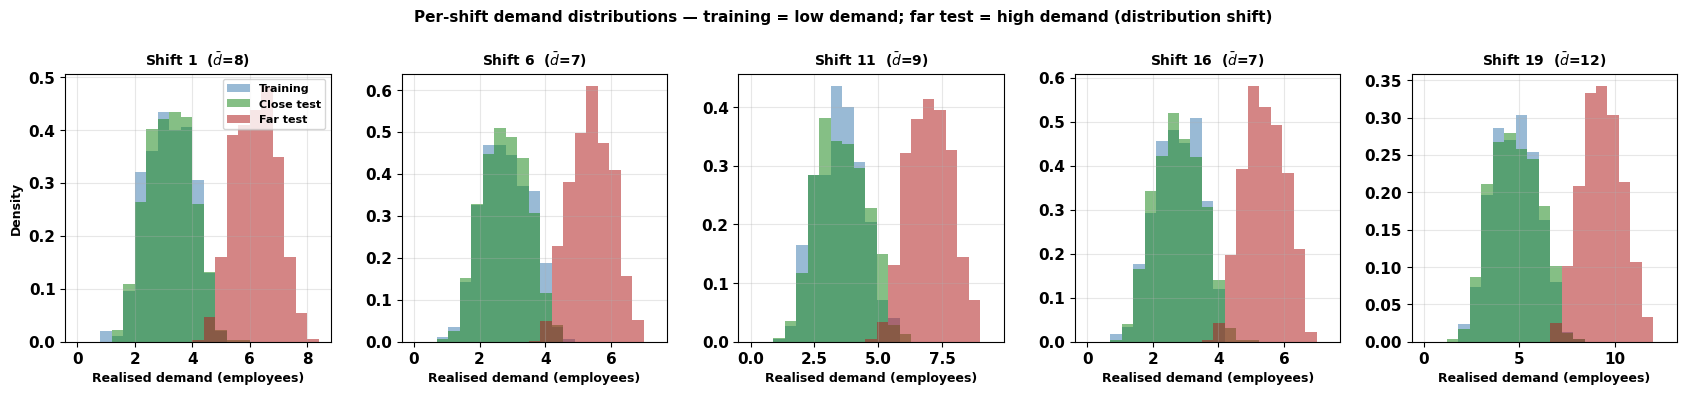

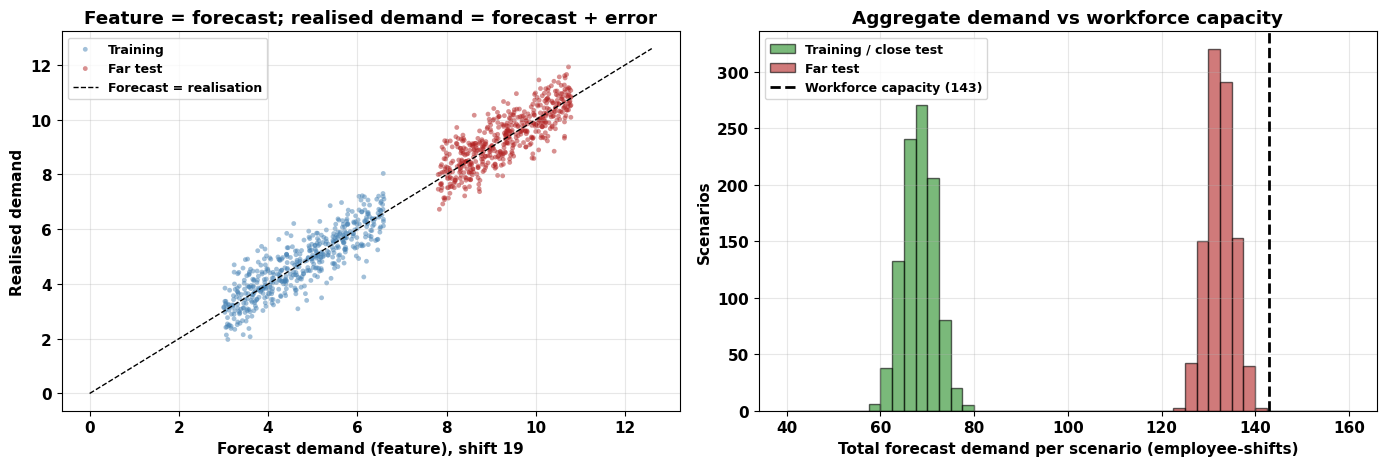

In [7]:
# ── Demand distributions: realised demand per shift (training / close / far) ──
show = [0, 5, 10, 15, int(np.argmax(D))]
fig, axes = plt.subplots(1, len(show), figsize=(17, 4))
for ax, j in zip(axes, show):
    bins = np.linspace(0, D[j] * 1.05, 22)
    ax.hist(d_tr[:500, j], bins=bins, alpha=0.55, color='steelblue',   density=True, label='Training')
    ax.hist(d_cl[:, j],    bins=bins, alpha=0.55, color='forestgreen', density=True, label='Close test')
    ax.hist(d_fa[:, j],    bins=bins, alpha=0.55, color='firebrick',   density=True, label='Far test')
    ax.set_title(f'Shift {j+1}  ($\\bar d$={D[j]:.0f})', fontsize=10)
    ax.set_xlabel('Realised demand (employees)', fontsize=9)
    ax.set_ylabel('Density' if j == show[0] else '', fontsize=9)
    ax.grid(True, alpha=0.3); boldticks(ax)
boldlegend(axes[0].legend(fontsize=8))
plt.suptitle('Per-shift demand distributions — training = low demand; far test = high demand (distribution shift)',
             fontsize=11, fontweight='bold')
plt.tight_layout(); save(fig, 'sa_large_demand_distributions'); plt.show()

# ── Forecast (feature) vs realised demand ────────────────────────────────────
j = int(np.argmax(D))
fig, ax = plt.subplots(1, 2, figsize=(14, 4.8))
ax[0].scatter(f_tr[:500, j]*D[j], d_tr[:500, j], s=12, alpha=.5, color='steelblue', label='Training', edgecolors='none')
ax[0].scatter(f_fa[:500, j]*D[j], d_fa[:500, j], s=12, alpha=.5, color='firebrick', label='Far test', edgecolors='none')
lim = [0, D[j]*1.05]; ax[0].plot(lim, lim, 'k--', lw=1, label='Forecast = realisation')
ax[0].set_xlabel(f'Forecast demand (feature), shift {j+1}'); ax[0].set_ylabel('Realised demand')
ax[0].set_title('Feature = forecast; realised demand = forecast + error')
ax[0].grid(True, alpha=.3); boldticks(ax[0]); boldlegend(ax[0].legend(fontsize=9))
bins = np.linspace(40, 160, 49)
ax[1].hist((f_cl*D).sum(1), bins=bins, color='forestgreen', alpha=.6, edgecolor='k', lw=.4, label='Training / close test')
ax[1].hist((f_fa*D).sum(1), bins=bins, color='firebrick',   alpha=.6, edgecolor='k', lw=.4, label='Far test')
ax[1].axvline(inst.smax_e.sum(), color='k', lw=2, ls='--', label=f'Workforce capacity ({inst.smax_e.sum()})')
ax[1].set_xlabel('Total forecast demand per scenario (employee-shifts)'); ax[1].set_ylabel('Scenarios')
ax[1].set_title('Aggregate demand vs workforce capacity')
ax[1].grid(True, alpha=.3); boldticks(ax[1]); boldlegend(ax[1].legend(fontsize=9, loc='upper left'))
plt.tight_layout(); save(fig, 'sa_large_forecast_vs_realised'); plt.show()

### Distribution shift between training, close-test and far-test data
(a) Empirical CDF of the forecast feature, pooled over shifts. (b) Density of the total forecast demand per scenario.
(c) Per-shift Wasserstein-1 distance of the forecast feature to the training data; the dashed line is the radius
$\rho=\alpha\bar W_1$ selected for the DR model ($\alpha=0.03$).

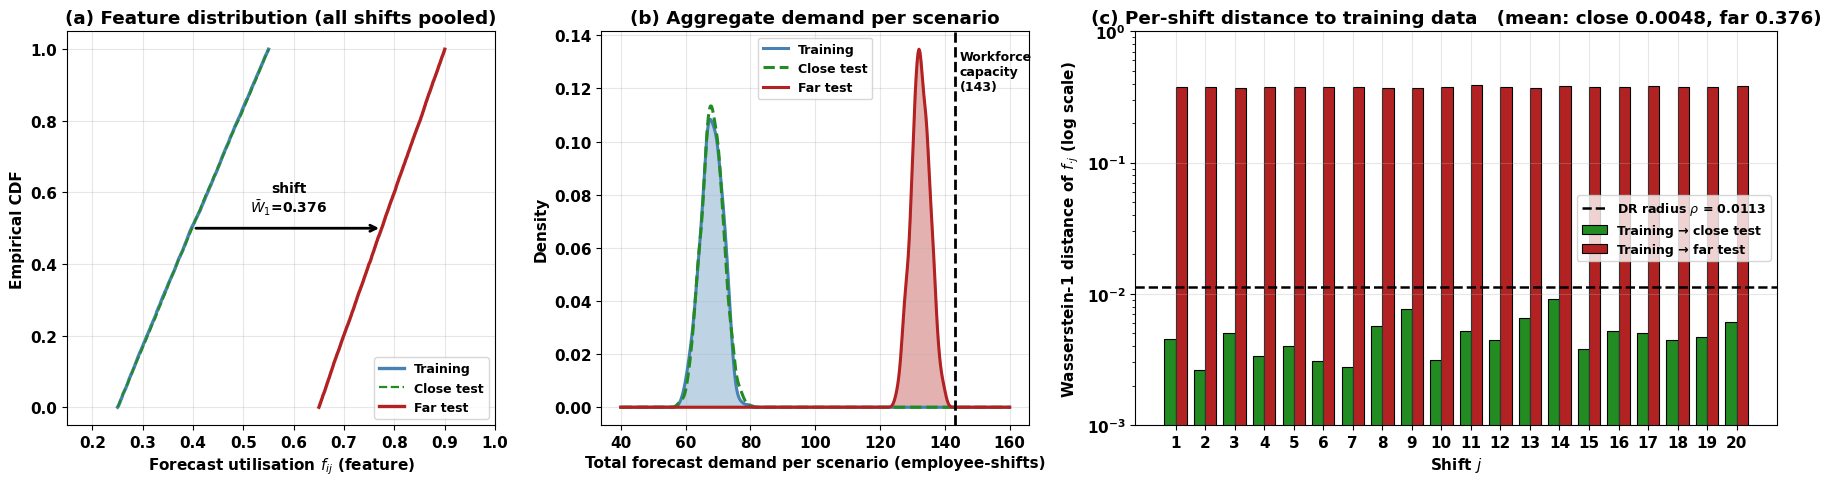

       set  mean forecast  mean total demand  W1 to training (mean over shifts)
  Training         0.3985            68.0679                             0.0000
Close test         0.3991            68.2224                             0.0048
  Far test         0.7747           132.4115                             0.3762


In [8]:
from scipy.stats import gaussian_kde
C3 = {'Training': 'steelblue', 'Close test': 'forestgreen', 'Far test': 'firebrick'}
sets = {'Training': (f_tr[:500], d_tr[:500]), 'Close test': (f_cl, d_cl), 'Far test': (f_fa, d_fa)}
wd_cl = np.array([wasserstein_distance(f_tr[:500, j], f_cl[:, j]) for j in range(J)])
wd_fa = np.array([wasserstein_distance(f_tr[:500, j], f_fa[:, j]) for j in range(J)])
rho_sel = 0.03 * W1_far

fig, ax = plt.subplots(1, 3, figsize=(18, 5), gridspec_kw={'width_ratios': [1, 1, 1.5]})
# (a) ECDF of the forecast feature
for nm, (f, d) in sets.items():
    v = np.sort(f.ravel()); ax[0].step(v, np.arange(1, len(v)+1)/len(v), where='post', lw=2.4 if nm != 'Close test' else 1.6,
                                       ls='-' if nm != 'Close test' else '--', color=C3[nm], label=nm)
ax[0].annotate('', xy=(0.775, 0.5), xytext=(0.40, 0.5), arrowprops=dict(arrowstyle='->', lw=2, color='k'))
ax[0].text(0.59, 0.53, f'shift\n$\\bar W_1$={W1_far:.3f}', ha='center', va='bottom', fontsize=10, fontweight='bold')
ax[0].set_xlabel('Forecast utilisation $f_{ij}$ (feature)'); ax[0].set_ylabel('Empirical CDF')
ax[0].set_title('(a) Feature distribution (all shifts pooled)'); ax[0].set_xlim(0.15, 1.0)
# (b) density of total forecast demand
grid = np.linspace(40, 160, 400)
for nm, (f, d) in sets.items():
    tot = (f*D).sum(1); kde = gaussian_kde(tot)
    ax[1].fill_between(grid, kde(grid), color=C3[nm], alpha=0.35 if nm != 'Close test' else 0.0)
    ax[1].plot(grid, kde(grid), color=C3[nm], lw=2.2, ls='-' if nm != 'Close test' else '--', label=nm)
ax[1].axvline(inst.smax_e.sum(), color='k', lw=2, ls='--')
ax[1].text(inst.smax_e.sum()+1.5, ax[1].get_ylim()[1]*0.95, f'Workforce\ncapacity\n({inst.smax_e.sum()})',
           va='top', ha='left', fontsize=9, fontweight='bold')
ax[1].set_xlabel('Total forecast demand per scenario (employee-shifts)'); ax[1].set_ylabel('Density')
ax[1].set_title('(b) Aggregate demand per scenario')
# (c) per-shift Wasserstein distances
xs = np.arange(J); bw2 = 0.38
ax[2].bar(xs - bw2/2, wd_cl, bw2, color=C3['Close test'], edgecolor='k', lw=0.8, label='Training → close test')
ax[2].bar(xs + bw2/2, wd_fa, bw2, color=C3['Far test'],   edgecolor='k', lw=0.8, label='Training → far test')
ax[2].axhline(rho_sel, color='k', lw=1.8, ls='--', label=f'DR radius $\\rho$ = {rho_sel:.4f}')
ax[2].set_yscale('log'); ax[2].set_ylim(1e-3, 1)
ax[2].set_xticks(xs); ax[2].set_xticklabels([str(j+1) for j in range(J)])
ax[2].set_xlabel('Shift $j$'); ax[2].set_ylabel('Wasserstein-1 distance of $f_{\\cdot j}$ (log scale)')
ax[2].set_title(f'(c) Per-shift distance to training data   (mean: close {wd_cl.mean():.4f}, far {wd_fa.mean():.3f})')
for a in ax:
    a.grid(True, alpha=0.3); boldticks(a)
boldlegend(ax[0].legend(fontsize=9, loc='lower right', frameon=True))
boldlegend(ax[1].legend(fontsize=9, loc='upper center', frameon=True))
boldlegend(ax[2].legend(fontsize=9, loc='center right', frameon=True))
plt.tight_layout(); save(fig, 'sa_large_distribution_shift'); plt.show()
print(pd.DataFrame({'set': list(sets), 'mean forecast': [f.mean() for f, d in sets.values()],
                    'mean total demand': [d.sum(1).mean() for f, d in sets.values()],
                    'W1 to training (mean over shifts)': [0.0, wd_cl.mean(), wd_fa.mean()]}).round(4).to_string(index=False))

## 2  Training (optional) and loading results

In [9]:
def run_experiment(SIZES, PRESC_ONLY=False, OUT='results'):
    """Train classical / prescriptive / DR prescriptive for each training size S and pickle results."""
    os.makedirs(OUT, exist_ok=True)
    ALPHAS = [0.05, 0.03, 0.02, 0.01, 0.005]; EPSS = [0.1, 0.2, 0.3]; C_ZETA = 10.0
    W1 = W1_far
    log = lambda *a: print(time.strftime('%H:%M:%S'), *a, flush=True)
    def ev(w, c):
        return dict(val=evaluate_policy(inst, w, c, f_va, d_va),
                    close=evaluate_policy(inst, w, c, f_cl, d_cl),
                    far=evaluate_policy(inst, w, c, f_fa, d_fa))

    hp = f'{OUT}/hindsight.pkl'
    if os.path.exists(hp):
        H = pickle.load(open(hp, 'rb'))
    else:
        t0 = time.time()
        H = {}
        for nm, d in [('close', d_cl), ('far', d_fa)]:
            xh = hindsight(inst, d); H[nm] = evaluate(inst, xh, d)
        pickle.dump(H, open(hp, 'wb')); log('hindsight', H, time.time() - t0)

    for S in SIZES:
        rp = f'{OUT}/res_S{S}.pkl'
        if os.path.exists(rp):
            continue
        R = dict(S=S); f, d = f_tr[:S], d_tr[:S]
        t0 = time.time(); w, c, _ = train_classical(inst, f, d, C_ZETA)
        R['classical'] = dict(eval=ev(w, c), time=time.time() - t0, w=w, c=c)
        log(S, 'classical', {k: round(v['total']) for k, v in R['classical']['eval'].items()})

        t0 = time.time(); pats = build_patterns(f)
        (w, c, L), info = train_bcd_multi(inst, f, d, pats, C_ZETA, restarts=2, ils=4, time_budget=1200)
        R['prescriptive'] = dict(eval=ev(w, c), time=time.time() - t0, obj=info['obj'], w=w, c=c, L=L)
        try:
            lb, tl = lp_bound(inst, f, d, pats, C_ZETA, time_limit=1200)
            R['prescriptive']['lp_bound'] = lb
        except Exception as ex:
            R['prescriptive']['lp_bound'] = None
        log(S, 'prescriptive', {k: round(v['total']) for k, v in R['prescriptive']['eval'].items()},
            'obj', round(info['obj'], 2), 'LB', R['prescriptive']['lp_bound'])

        if PRESC_ONLY:
            pickle.dump(R, open(rp, 'wb')); log(S, 'DONE (prescriptive only)'); continue
        tune = []; best = None
        for a in ALPHAS:
            rho = a * W1; found = []
            for eps in EPSS:
                t0 = time.time(); pr = build_patterns(f, rho, eps)
                res, info = train_bcd_multi(inst, f, d, pr, C_ZETA, dr=dict(rho=rho, eps=eps),
                                            restarts=1, ils=0, time_budget=900)
                el = time.time() - t0
                if res is None:
                    tune.append(dict(alpha=a, rho=rho, eps=eps, feasible=False, time=el))
                    log(S, 'DR', a, eps, 'infeasible'); continue
                w, c, L = res; E_ = ev(w, c)
                row = dict(alpha=a, rho=rho, eps=eps, feasible=True, time=el, eval=E_, w=w, c=c, L=L,
                           n_adaptive=int((np.abs(w) > 1e-9).sum()))
                tune.append(row); found.append(row)
                log(S, 'DR', a, eps, {k: round(v['total']) for k, v in E_.items()}, 'adaptive', row['n_adaptive'], round(el))
            if found:   # protocol: largest feasible radius, epsilon by validation cost
                best = min(found, key=lambda r: r['eval']['val']['total']); break
        R['dr_tuning'] = tune; R['drcc'] = best
        pickle.dump(R, open(rp, 'wb'))
        log(S, 'DONE')

In [10]:
if RUN_EXPERIMENTS:
    run_experiment([50, 100, 200, 500])
H = pickle.load(open('results/hindsight.pkl', 'rb'))
R = {}
for p in glob.glob('results/res_S*.pkl'):
    r = pickle.load(open(p, 'rb')); R[r['S']] = r
SIZES = sorted(R)
rows = []
for S in SIZES:
    for m in MODELS:
        if R[S].get(m) is None: continue
        for t in ['close', 'far']:
            e = R[S][m]['eval'][t]
            rows.append(dict(S=S, model=LAB[m], test=t, staff=e['staff'], shortage=e['shortage'], total=e['total']))
df = pd.DataFrame(rows)
tab = df.pivot_table(index=['S', 'model'], columns='test', values=['staff', 'shortage', 'total']).round(0)
print('Hindsight (mean cost/scenario):', {k: round(v['total']) for k, v in H.items()})
for S in SIZES:
    p = R[S]['prescriptive']; lb = p.get('lp_bound')
    gap = f"{100*(p['obj']-lb)/lb:.1f}%" if lb and lb > 0.5*p['obj'] else 'n/a'
    hp = R[S].get('drcc'); hp = f"alpha={hp['alpha']}, eps={hp['eps']}" if hp else '-'
    print(f'S={S:>3}: prescriptive optimality gap (LP bound) {gap:>5};  DR hyperparameters: {hp}')
tab

Hindsight (mean cost/scenario): {'close': 762, 'far': 1685}
S= 50: prescriptive optimality gap (LP bound)  2.6%;  DR hyperparameters: alpha=0.03, eps=0.3
S=100: prescriptive optimality gap (LP bound)  3.0%;  DR hyperparameters: alpha=0.03, eps=0.3
S=200: prescriptive optimality gap (LP bound)  3.2%;  DR hyperparameters: alpha=0.03, eps=0.3
S=500: prescriptive optimality gap (LP bound)   n/a;  DR hyperparameters: alpha=0.03, eps=0.3


shortage            staff          \
test                                         close      far   close     far   
S   model                                                                     
50  Classical                               2262.0  27207.0   700.0   764.0   
    Distributionally robust\nprescriptive      0.0   6275.0  1263.0  1375.0   
    Prescriptive                             155.0  15852.0   916.0  1061.0   
100 Classical                               2396.0  27706.0   692.0   751.0   
    Distributionally robust\nprescriptive      0.0   5269.0  1310.0  1417.0   
    Prescriptive                              52.0  12879.0   965.0  1139.0   
200 Classical                               2343.0  27706.0   696.0   751.0   
    Distributionally robust\nprescriptive      0.0   5051.0  1322.0  1431.0   
    Prescriptive                              18.0  11462.0  1011.0  1179.0   
500 Classical                               2389.0  27206.0   695.0   762.0   
    Distributionally robust\nprescriptive      0.0   4379.0  1358.0  1459.0   
    Prescriptive                               8.0   8364.0  1052.0  1277.0   

                                            total           
test                                        close      far  
S   model                                                   
50  Classical                              2962.0  27971.0  
    Distributionally robust\nprescriptive  1264.0   7650.0  
    Prescriptive                           1071.0  16913.0  
100 Classical                              3089.0  28457.0  
    Distributionally robust\nprescriptive  1310.0   6686.0  
    Prescriptive                           1017.0  14018.0  
200 Classical                              3039.0  28457.0  
    Distributionally robust\nprescriptive  1322.0   6482.0  
    Prescriptive                           1029.0  12641.0  
500 Classical                              3084.0  27968.0  
    Distributionally robust\nprescriptive  1358.0   5838.0  
    Prescriptive                           1060.0   9641.0

### Check: the policy never sees realised demand
Deployment decisions are $x=\mathbb I\{w z + w^0\ge 0.5\}$ with $z$ = **forecast**. Below, the schedules are built from forecasts only and
scored on realised demand (the gap to the forecast-scored cost is the price of forecast error).
During training, realised demand $d$ enters only the coverage constraints (38d)/(43) (as the uncertain parameter
$\theta$, observed historically) and the oracle labels of the classical model — never the feature vector.

In [11]:
# The deployed schedule is computed from (w, c) and the forecast f only; d is passed only to the scorer.
import inspect
assert 'd' not in inspect.signature(predict).parameters and 'd' not in inspect.signature(repair_workload).parameters
for S in SIZES:
    for m in MODELS:
        if R[S].get(m) is None: continue
        w, c = R[S][m]['w'], R[S][m]['c']
        x = repair_workload(inst, predict(w, c, f_fa), f_fa)          # uses forecasts only
        r_true = evaluate(inst, x, d_fa)                               # scored on realised demand
        r_fc   = evaluate(inst, x, f_fa * D)                           # what the forecast would suggest
        if m == 'drcc' or (m == 'prescriptive' and S == 500):
            print(f'S={S:>3} {LAB[m].replace(chr(10)," "):<38} far-test total: realised {r_true["total"]:>9,.0f}'
                  f'  | if demand equalled its forecast {r_fc["total"]:>9,.0f}')
print('\nOK: schedules depend on the forecast only; realised demand is used for training constraints/labels and scoring.')

S= 50 Distributionally robust prescriptive   far-test total: realised     7,650  | if demand equalled its forecast     7,313
S=100 Distributionally robust prescriptive   far-test total: realised     6,686  | if demand equalled its forecast     6,312
S=200 Distributionally robust prescriptive   far-test total: realised     6,482  | if demand equalled its forecast     6,113
S=500 Prescriptive                           far-test total: realised     9,641  | if demand equalled its forecast     9,358
S=500 Distributionally robust prescriptive   far-test total: realised     5,838  | if demand equalled its forecast     5,435

OK: schedules depend on the forecast only; realised demand is used for training constraints/labels and scoring.


## 3  Out-of-sample costs at $S=100$ (staffing / shortage / total)

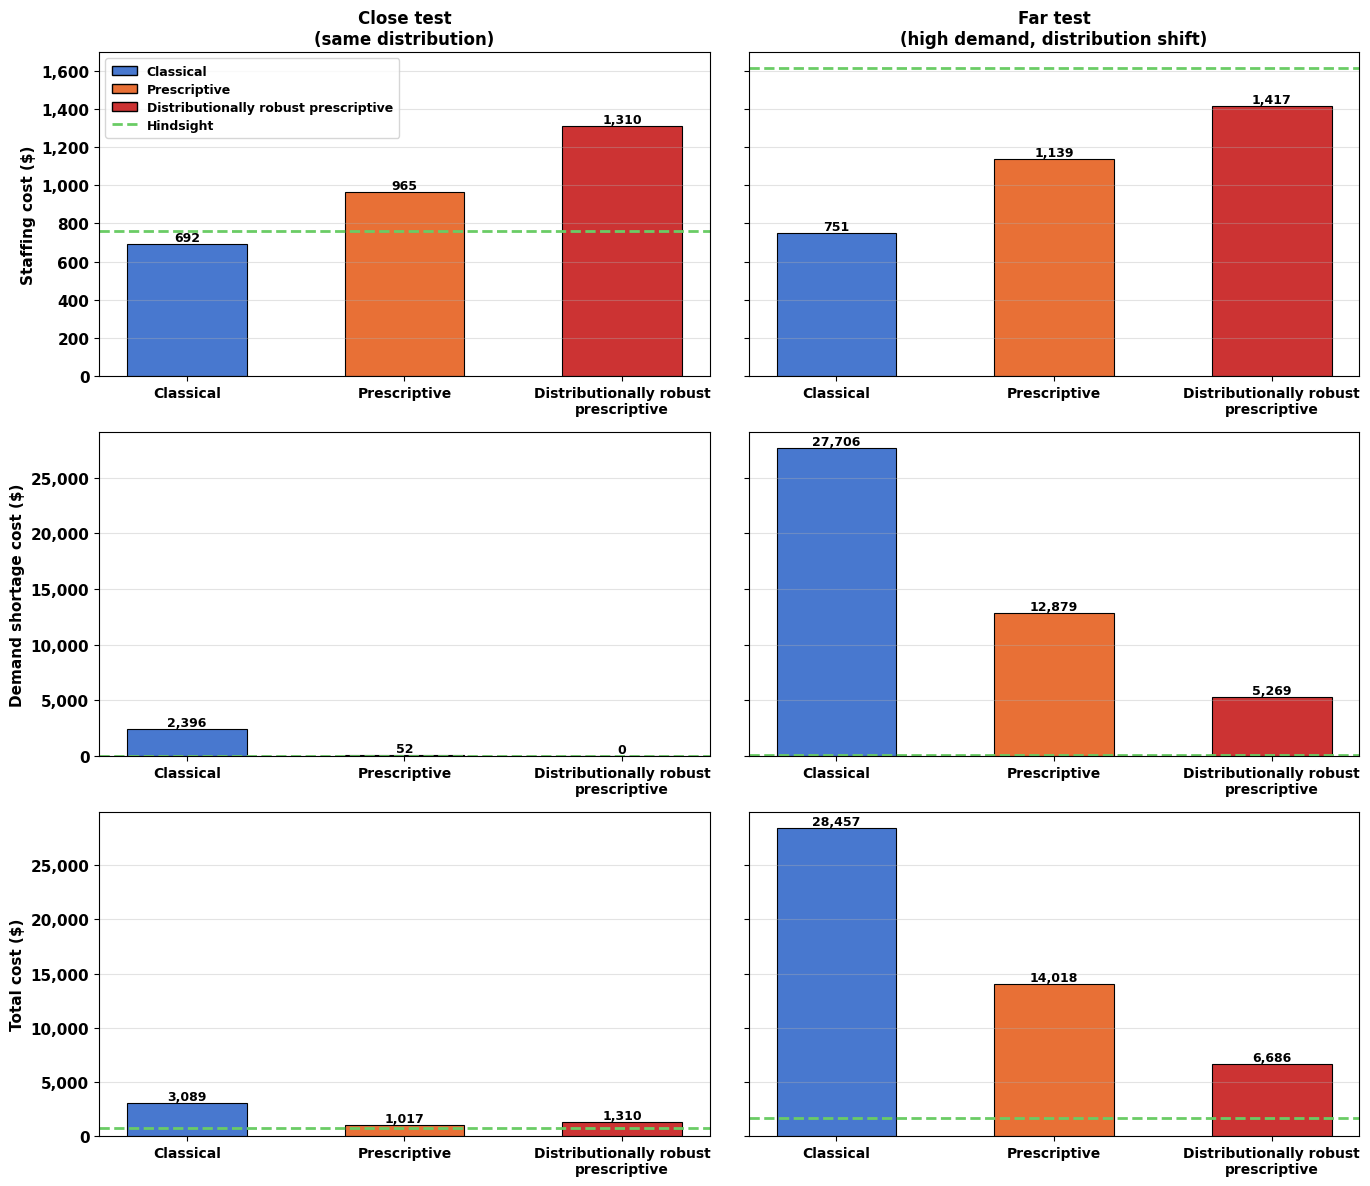

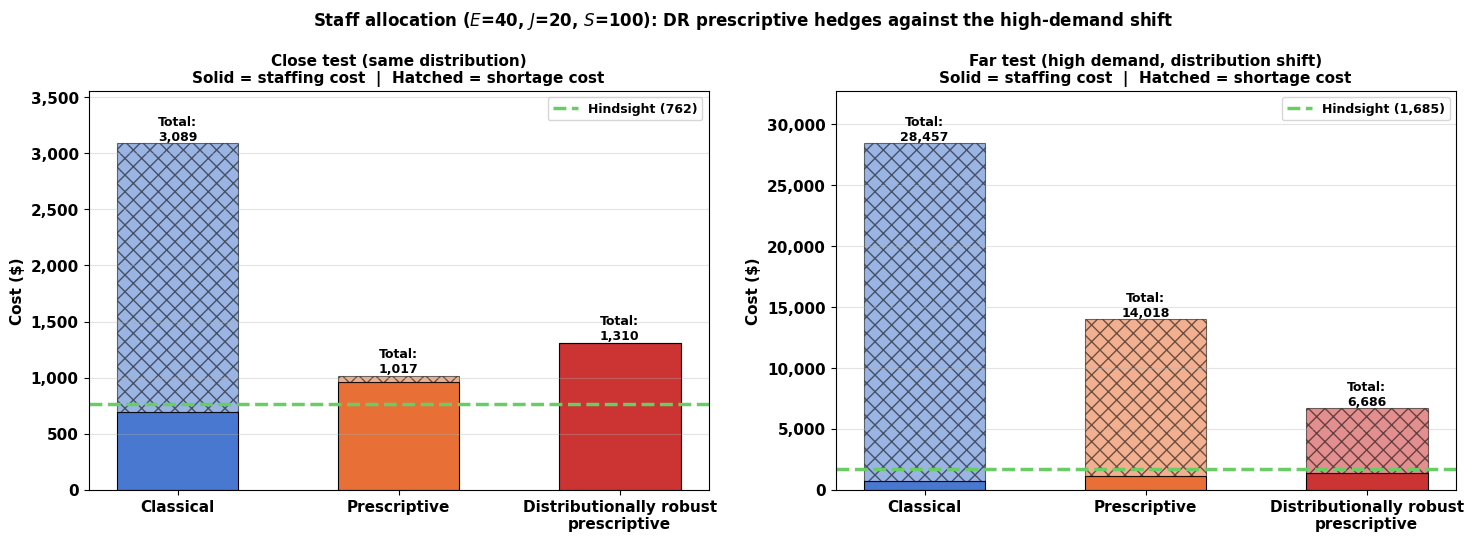

In [16]:
S0 = 100
x3 = np.arange(3); bw = 0.55
fields  = ['staff', 'shortage', 'total']
ylabels = ['Staffing cost ($)', 'Demand shortage cost ($)', 'Total cost ($)']
groups  = [('close', 'Close test\n(same distribution)'), ('far', 'Far test\n(high demand, distribution shift)')]

fig, axes = plt.subplots(3, 2, figsize=(14, 12), sharey='row')
for row, (field, ylabel) in enumerate(zip(fields, ylabels)):
    for col, (t, grp) in enumerate(groups):
        ax = axes[row, col]
        vals = [R[S0][m]['eval'][t][field] for m in MODELS]
        bars = ax.bar(x3, vals, width=bw, color=[COL[m] for m in MODELS], edgecolor='k', linewidth=0.8)
        ax.axhline(H[t][field], color=HCOL, lw=2, ls='--')
        for bar, v in zip(bars, vals):
            ax.text(bar.get_x() + bar.get_width()/2, bar.get_height(), f'{v:,.0f}',
                    ha='center', va='bottom', fontsize=9, fontweight='bold')
        ax.set_xticks(x3); ax.set_xticklabels([LAB[m] for m in MODELS], fontsize=10, fontweight='bold')
        ax.set_ylabel(ylabel if col == 0 else '', fontsize=11, fontweight='bold')
        ax.grid(axis='y', alpha=0.35); ax.yaxis.set_major_formatter(fmt); boldticks(ax)
        if row == 0:
            ax.set_title(grp, fontsize=12, fontweight='bold')
legend_models(axes[0, 0])
plt.tight_layout(); save(fig, 'sa_large_oos_results'); plt.show()
fig.savefig('method_comparison.pdf', bbox_inches='tight')

# ── Stacked view: solid = staffing, hatched = shortage ───────────────────────
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
for ax, (t, grp) in zip(axes, groups):
    staff = [R[S0][m]['eval'][t]['staff'] for m in MODELS]
    short = [R[S0][m]['eval'][t]['shortage'] for m in MODELS]
    cols = [COL[m] for m in MODELS]
    ax.bar(x3, staff, width=bw, color=cols, edgecolor='k', lw=0.8)
    ax.bar(x3, short, width=bw, bottom=staff, color=cols, edgecolor='k', lw=0.8, hatch='xx', alpha=0.55)
    for i, (s, sh) in enumerate(zip(staff, short)):
        ax.text(i, s + sh, f'Total:\n{s+sh:,.0f}', ha='center', va='bottom', fontsize=9, fontweight='bold')
    ax.axhline(H[t]['total'], color=HCOL, lw=2.5, ls='--', label=f"Hindsight ({H[t]['total']:,.0f})")
    ax.set_xticks(x3); ax.set_xticklabels([LAB[m] for m in MODELS], fontsize=11, fontweight='bold')
    ax.set_ylabel('Cost ($)', fontweight='bold'); ax.grid(axis='y', alpha=0.35)
    ax.yaxis.set_major_formatter(fmt); boldticks(ax)
    ax.set_ylim(0, 1.15 * max(s + sh for s, sh in zip(staff, short)))
    ax.set_title(grp.replace('\n', ' ') + '\nSolid = staffing cost  |  Hatched = shortage cost', fontsize=11, fontweight='bold')
    boldlegend(ax.legend(fontsize=9, loc='upper right'))
fig.suptitle(f'Staff allocation ($E$={inst.E}, $J$={inst.J}, $S$={S0}): DR prescriptive hedges against the high-demand shift',
             fontsize=12, fontweight='bold')
plt.tight_layout(); save(fig, 'sa_large_oos_stacked'); plt.show()


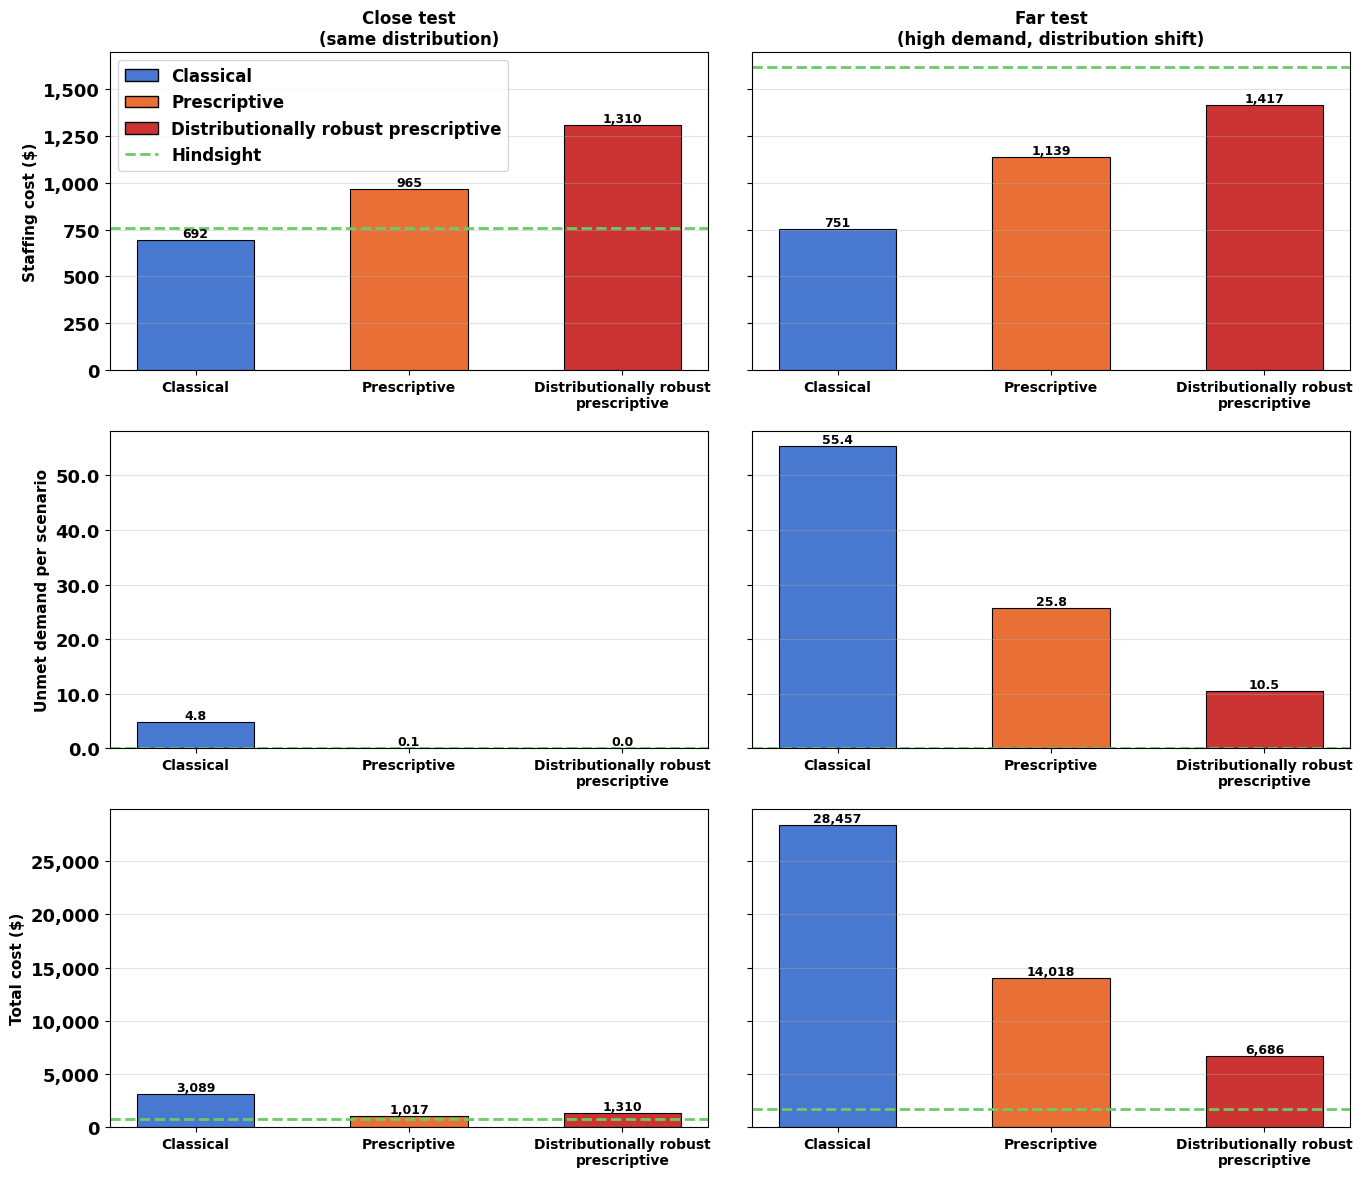

In [ ]:
plt.rcParams.update({'font.size': 14,          # base size (ticks, legend default)
                     'axes.labelsize': 20,     # axis labels
                     'axes.titlesize': 18,     # subplot titles
                     'xtick.labelsize': 13,
                     'ytick.labelsize': 13,
                     'legend.fontsize': 14})

S0 = 100
x3 = np.arange(3); bw = 0.55
fields  = ['staff', 'shortage', 'total']
ylabels = ['Staffing cost ($)', 'Unmet demand per scenario', 'Total cost ($)']
groups  = [('close', 'Close test\n(same distribution)'), ('far', 'Far test\n(high demand, distribution shift)')]

def metric(res, field):
    """Row 2 shows the amount of unmet demand (shortage cost / c_ls), not its cost."""
    return res[field] / inst.c_ls if field == 'shortage' else res[field]

fig, axes = plt.subplots(3, 2, figsize=(14, 12), sharey='row')
for row, (field, ylabel) in enumerate(zip(fields, ylabels)):
    for col, (t, grp) in enumerate(groups):
        ax = axes[row, col]
        vals = [metric(R[S0][m]['eval'][t], field) for m in MODELS]
        bars = ax.bar(x3, vals, width=bw, color=[COL[m] for m in MODELS], edgecolor='k', linewidth=0.8)
        ax.axhline(metric(H[t], field), color=HCOL, lw=2, ls='--')
        lab_fmt = '{:,.1f}' if field == 'shortage' else '{:,.0f}'
        for bar, v in zip(bars, vals):
            ax.text(bar.get_x() + bar.get_width()/2, bar.get_height(), lab_fmt.format(v),
                    ha='center', va='bottom', fontsize=9, fontweight='bold')
        ax.set_xticks(x3); ax.set_xticklabels([LAB[m] for m in MODELS], fontsize=10, fontweight='bold')
        ax.set_ylabel(ylabel if col == 0 else '', fontsize=11, fontweight='bold')
        ax.grid(axis='y', alpha=0.35)
        ax.yaxis.set_major_formatter(mt.FuncFormatter(lambda v, _: f'{v:,.0f}') if field != 'shortage'
                                     else mt.FuncFormatter(lambda v, _: f'{v:,.1f}'))
        boldticks(ax)
        if row == 0:
            ax.set_title(grp, fontsize=12, fontweight='bold')
legend_models(axes[0, 0])   # →
leg = axes[0, 0].legend(handles=[Patch(fc=COL[m], ec='k', label=LAB[m].replace('\n', ' ')) for m in MODELS]
                        + [Line2D([0], [0], color=HCOL, lw=2, ls='--', label='Hindsight')],
                        fontsize=15, frameon=True, loc='upper left')
boldlegend(leg)
plt.tight_layout()
fig.savefig('method_comparison.pdf', bbox_inches='tight')   # save BEFORE show
save(fig, 'sa_large_oos_results')
plt.show()

## 4  Sample-size sensitivity: more data does not replace robustness

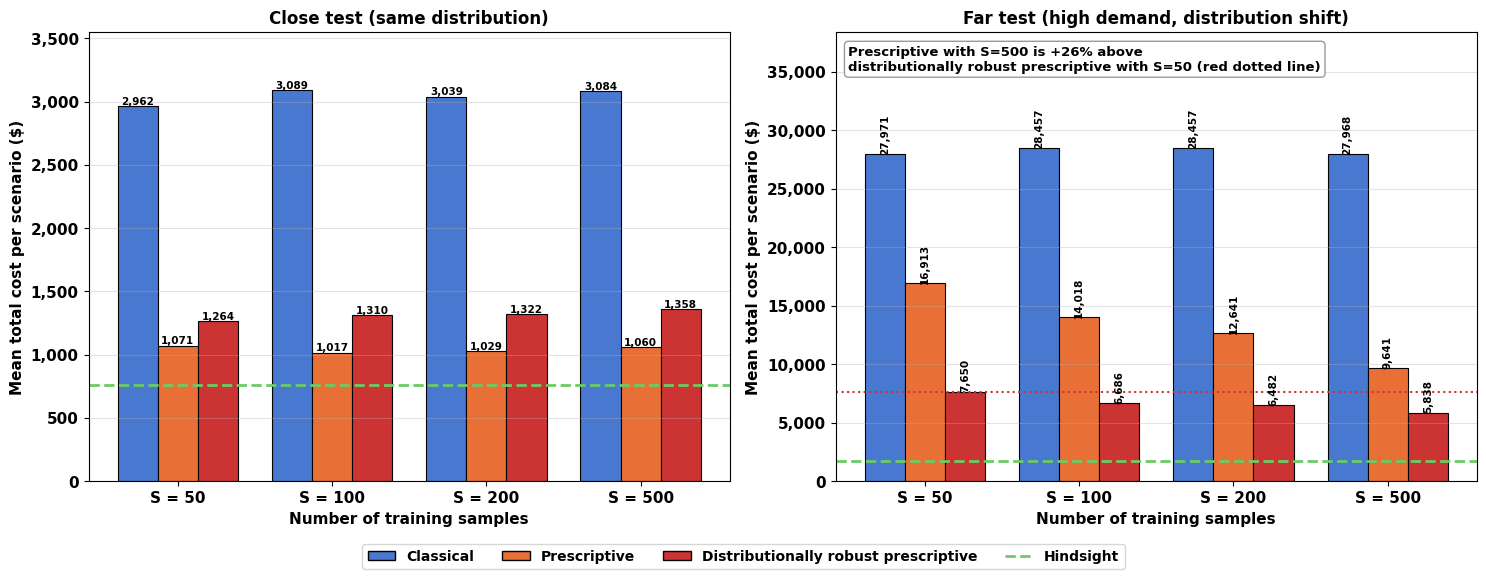

Far test: prescriptive S=500 9,641; DR S=50 7,650 (+26%); DR S=100 6,686


In [20]:
# ── Total cost vs number of training samples (grouped bars) ──────────────────
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
xs = np.arange(len(SIZES)); bw3 = 0.26
for ax, (t, grp) in zip(axes, [('close', 'Close test (same distribution)'),
                               ('far', 'Far test (high demand, distribution shift)')]):
    for k, m in enumerate(MODELS):
        vals = [R[S][m]['eval'][t]['total'] if R[S].get(m) else np.nan for S in SIZES]
        bars = ax.bar(xs + (k-1)*bw3, vals, width=bw3, color=COL[m], edgecolor='k', linewidth=0.8)
        for b, v in zip(bars, vals):
            if np.isfinite(v):
                ax.text(b.get_x() + b.get_width()/2, v, f'{v:,.0f}', ha='center', va='bottom',
                        fontsize=7.5, fontweight='bold', rotation=90 if t == 'far' else 0)
    ax.axhline(H[t]['total'], color=HCOL, lw=2, ls='--')
    ax.set_xticks(xs); ax.set_xticklabels([f'S = {S}' for S in SIZES], fontsize=11, fontweight='bold')
    ax.set_xlabel('Number of training samples', fontweight='bold')
    ax.set_ylabel('Mean total cost per scenario ($)', fontweight='bold')
    ax.grid(axis='y', alpha=0.35); ax.yaxis.set_major_formatter(fmt); boldticks(ax)
    ax.set_title(grp, fontsize=12, fontweight='bold')
axes[1].set_ylim(0, 1.35*max(R[S]['classical']['eval']['far']['total'] for S in SIZES))
axes[0].set_ylim(0, 1.15*max(R[S]['classical']['eval']['close']['total'] for S in SIZES))
p500 = R[500]['prescriptive']['eval']['far']['total']; d50 = R[50]['drcc']['eval']['far']['total']
axes[1].axhline(d50, color=COL['drcc'], lw=1.5, ls=':')
# axes[1].text(0.02, 0.97, f'Prescriptive with S=500 ({p500:,.0f}) is +{100*(p500/d50-1):.0f}% above\n'
#              f'DR prescriptive with S=50 ({d50:,.0f}, dotted line)', transform=axes[1].transAxes,
#              va='top', ha='left', fontsize=9.5, fontweight='bold',
#              bbox=dict(boxstyle='round', fc='white', ec='0.6'))
axes[1].text(0.02, 0.97, f'Prescriptive with S=500 is +{100*(p500/d50-1):.0f}% above\n'
             f'distributionally robust prescriptive with S=50 (red dotted line)', transform=axes[1].transAxes,
             va='top', ha='left', fontsize=9.5, fontweight='bold',
             bbox=dict(boxstyle='round', fc='white', ec='0.6'))
h = [Patch(fc=COL[m], ec='k', label=LAB[m].replace('\n', ' ')) for m in MODELS] + \
    [Line2D([0], [0], color=HCOL, lw=2, ls='--', label='Hindsight')]
boldlegend(fig.legend(handles=h, loc='lower center', ncol=4, fontsize=10, frameon=True, bbox_to_anchor=(0.5, -0.06)))
plt.tight_layout()
fig.savefig('sample_size_comparison.pdf', bbox_inches='tight')   # save BEFORE show
save(fig, 'sa_large_sample_size')                                # also writes figures/*.pdf and *.png
plt.show()
print(f'Far test: prescriptive S=500 {p500:,.0f}; DR S=50 {d50:,.0f} (+{100*(p500/d50-1):.0f}%); '
      f'DR S=100 {R[100]["drcc"]["eval"]["far"]["total"]:,.0f}')

## 5  Why in-distribution cost rises with $S$

Coverage (38d) is a **hard constraint in every training sample**. Because the policy sees only the forecast, it must
carry a safety buffer against the forecast error, and that buffer is set by the *worst* error among the $S$ training
samples. For Gaussian errors, $\mathbb E[\max_{i\le S}\eta_i]\approx 2.25,\,2.51,\,2.75,\,3.04$ for $S=50,100,200,500$.
The required service level therefore approaches 100%, while the cost-optimal (newsvendor) level is
$1-\bar c/c^{\rm ls}\approx 98\%$: staffing cost rises faster than shortage cost falls. This is the scenario-approach
logic — feasibility on $S$ samples is roughly a $1/S$ violation level — and it makes prescriptive learning itself a
feasibility-robust method that tightens with data. What more data **cannot** provide is protection against a shifted
regime; that is what the Wasserstein ball adds.

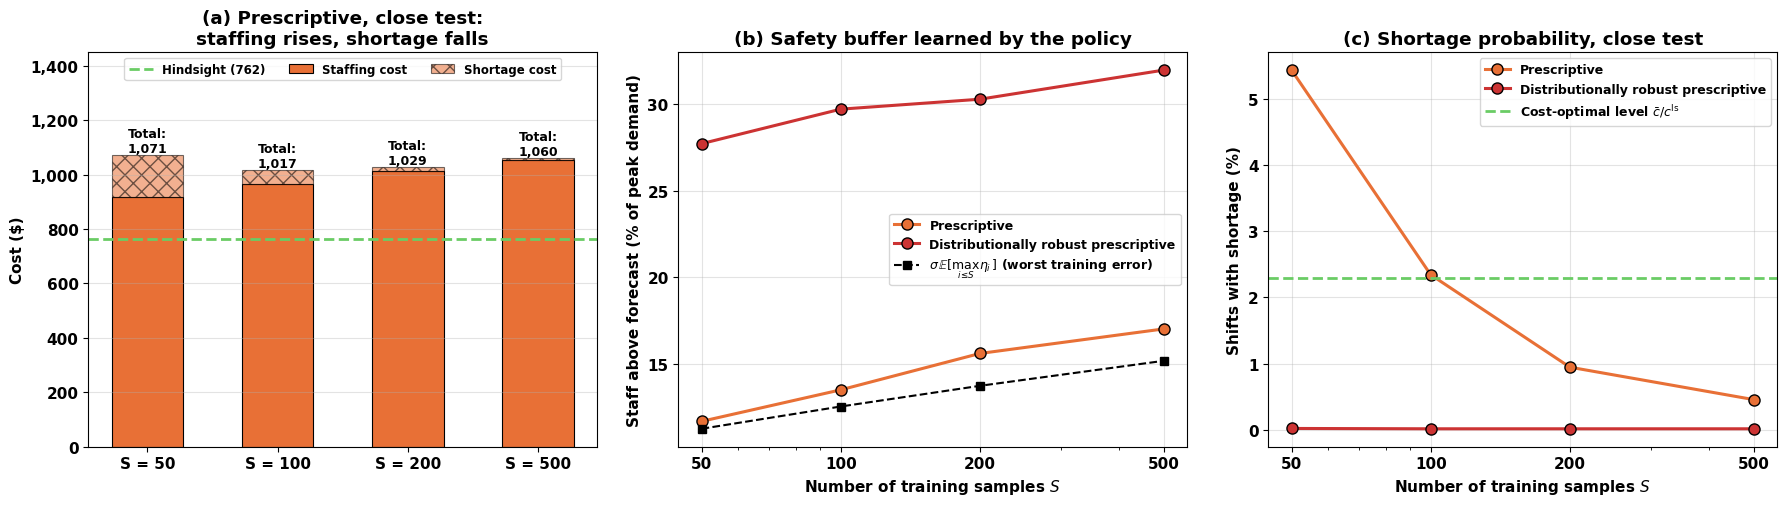

  S  E[max eta]  presc buffer %  presc P(short) %
 50        2.25            11.7              5.43
100        2.51            13.5              2.34
200        2.75            15.6              0.94
500        3.04            17.0              0.46


In [14]:
Ssim = np.array(SIZES)
rng = np.random.default_rng(0)
emax = np.array([rng.standard_normal((20000, S)).max(1).mean() for S in Ssim])
sigma = 0.05
def stats(m, S):
    w, c = R[S][m]['w'], R[S][m]['c']
    x = repair_workload(inst, predict(w, c, f_cl), f_cl)
    staffed = x.sum(1)
    return ((staffed - f_cl*D) / D).mean(), (staffed < d_cl - 1e-9).mean()
B = {m: np.array([stats(m, S) for S in SIZES if R[S].get(m)]) for m in ['prescriptive', 'drcc']}
cbar = inst.c_e.mean()
xs = np.arange(len(SIZES))

fig, ax = plt.subplots(1, 3, figsize=(18, 5.2))
# (a) staffing + shortage of the prescriptive model on the close test
st = [R[S]['prescriptive']['eval']['close']['staff'] for S in SIZES]
sh = [R[S]['prescriptive']['eval']['close']['shortage'] for S in SIZES]
ax[0].bar(xs, st, 0.55, color=COL['prescriptive'], edgecolor='k', lw=0.8, label='Staffing cost')
ax[0].bar(xs, sh, 0.55, bottom=st, color=COL['prescriptive'], edgecolor='k', lw=0.8, hatch='xx', alpha=0.55,
          label='Shortage cost')
for i in range(len(SIZES)):
    ax[0].text(xs[i], st[i] + sh[i], f'Total:\n{st[i]+sh[i]:,.0f}', ha='center', va='bottom', fontsize=9, fontweight='bold')
ax[0].axhline(H['close']['total'], color=HCOL, lw=2, ls='--', label=f"Hindsight ({H['close']['total']:,.0f})")
ax[0].set_xticks(xs); ax[0].set_xticklabels([f'S = {S}' for S in SIZES], fontweight='bold')
ax[0].set_ylim(0, 1450); ax[0].set_ylabel('Cost ($)'); ax[0].yaxis.set_major_formatter(fmt)
ax[0].set_title('(a) Prescriptive, close test:\nstaffing rises, shortage falls')
boldlegend(ax[0].legend(fontsize=8.5, loc='upper center', ncol=3, frameon=True))
# (b) safety buffer
for m in ['prescriptive', 'drcc']:
    s_ = [S for S in SIZES if R[S].get(m)]
    ax[1].plot(s_, 100*B[m][:, 0], 'o-', color=COL[m], lw=2.2, ms=8, mec='k', label=LAB[m].replace('\n', ' '))
ax[1].plot(Ssim, 100*sigma*emax, 's--', color='k', lw=1.5, ms=6, label=r'$\sigma\,\mathbb{E}[\max_{i\leq S}\eta_i]$ (worst training error)')
ax[1].set_xscale('log'); ax[1].set_xticks(SIZES); ax[1].set_xticklabels(SIZES); ax[1].xaxis.set_minor_formatter(mt.NullFormatter())
ax[1].set_xlabel('Number of training samples $S$'); ax[1].set_ylabel('Staff above forecast (% of peak demand)')
ax[1].set_title('(b) Safety buffer learned by the policy')
boldlegend(ax[1].legend(fontsize=9, loc='center right', frameon=True))
# (c) shortage probability
for m in ['prescriptive', 'drcc']:
    s_ = [S for S in SIZES if R[S].get(m)]
    ax[2].plot(s_, 100*B[m][:, 1], 'o-', color=COL[m], lw=2.2, ms=8, mec='k', label=LAB[m].replace('\n', ' '))
ax[2].axhline(100*cbar/inst.c_ls, color=HCOL, lw=2, ls='--', label=r'Cost-optimal level $\bar c/c^{\rm ls}$')
ax[2].set_xscale('log'); ax[2].set_xticks(SIZES); ax[2].set_xticklabels(SIZES); ax[2].xaxis.set_minor_formatter(mt.NullFormatter())
ax[2].set_xlabel('Number of training samples $S$'); ax[2].set_ylabel('Shifts with shortage (%)')
ax[2].set_title('(c) Shortage probability, close test')
boldlegend(ax[2].legend(fontsize=9, loc='upper right', frameon=True))
for a in ax:
    a.grid(axis='y' if a is ax[0] else 'both', alpha=0.35); boldticks(a)
plt.tight_layout(); save(fig, 'sa_large_mechanism'); plt.show()
print(pd.DataFrame({'S': SIZES, 'E[max eta]': emax.round(2),
                    'presc buffer %': (100*B['prescriptive'][:, 0]).round(1),
                    'presc P(short) %': (100*B['prescriptive'][:, 1]).round(2)}).to_string(index=False))

## 6  Table for the paper

In [15]:
lines = []
for S in SIZES:
    for m in MODELS:
        if R[S].get(m) is None: continue
        e = R[S][m]['eval']
        v = [e['close']['staff'], e['close']['shortage'], e['close']['total'],
             e['far']['staff'], e['far']['shortage'], e['far']['total']]
        lines.append(f"{S if m == 'classical' else ''} & {LAB[m].replace(chr(10), ' ')} & " + ' & '.join(f'{x:,.0f}' for x in v) + r' \\')
    lines.append(r'\addlinespace')
print('\n'.join(lines[:-1]))

50 & Classical & 700 & 2,262 & 2,962 & 764 & 27,207 & 27,971 \\
 & Prescriptive & 916 & 155 & 1,071 & 1,061 & 15,852 & 16,913 \\
 & Distributionally robust prescriptive & 1,263 & 0 & 1,264 & 1,375 & 6,275 & 7,650 \\
\addlinespace
100 & Classical & 692 & 2,396 & 3,089 & 751 & 27,706 & 28,457 \\
 & Prescriptive & 965 & 52 & 1,017 & 1,139 & 12,879 & 14,018 \\
 & Distributionally robust prescriptive & 1,310 & 0 & 1,310 & 1,417 & 5,269 & 6,686 \\
\addlinespace
200 & Classical & 696 & 2,343 & 3,039 & 751 & 27,706 & 28,457 \\
 & Prescriptive & 1,011 & 18 & 1,029 & 1,179 & 11,462 & 12,641 \\
 & Distributionally robust prescriptive & 1,322 & 0 & 1,322 & 1,431 & 5,051 & 6,482 \\
\addlinespace
500 & Classical & 695 & 2,389 & 3,084 & 762 & 27,206 & 27,968 \\
 & Prescriptive & 1,052 & 8 & 1,060 & 1,277 & 8,364 & 9,641 \\
 & Distributionally robust prescriptive & 1,358 & 0 & 1,358 & 1,459 & 4,379 & 5,838 \\
